# Evaluación Científica Definitiva — `SM-CFHR` (`AdaptiveStructuredHuberRegressor`)

Informe computacional autónomo que sigue la progresión **Pregunta → Código → Resultado → Interpretación → Conclusión** a partir de los artefactos OOF definitivos cerrados en `resultados/evaluacion_ashr_oof/` **sin repetir entrenamientos** (`Fixed`: `14,625/14,625`; `HPO`: `14,625/14,625`).

## Índice navegable
1. [Capítulo 1. Problema, alcance, versiones, formulación e integridad OOF](#Capítulo-1.-Problema,-alcance,-versiones,-formulación-e-integridad-OOF)
2. [Capítulo 2. Auditoría de optimización (Optuna TPE) y validación causal anidada](#Capítulo-2.-Auditoría-de-optimización-(Optuna-TPE)-y-validación-causal-anidada)
3. [Capítulo 3. SM-CFHR frente a modelos de biblioteca — Evaluación del criterio docente](#Capítulo-3.-SM-CFHR-frente-a-modelos-de-biblioteca-—-Evaluación-del-criterio-docente)
4. [Capítulo 4. Comparación general (23 modelos), inferencia estadística y evaluador R3](#Capítulo-4.-Comparación-general-(23-modelos),-inferencia-estadística-y-evaluador-R3)
5. [Capítulo 5. Evaluación intra-dataset (plantas, capacidad, periodos, clima y estrategia)](#Capítulo-5.-Evaluación-intra-dataset-(plantas,-capacidad,-periodos,-clima-y-estrategia))
6. [Capítulo 6. Evaluación inter-planta e inter-grupo geográfico (alcance real sin datasets externos)](#Capítulo-6.-Evaluación-inter-planta-e-inter-grupo-geográfico-(alcance-real-sin-datasets-externos))
7. [Capítulo 7. Fixed frente a HPO, estudios diagnósticos reales (D+1) y coste computacional](#Capítulo-7.-Fixed-frente-a-HPO,-estudios-diagnósticos-reales-(D+1)-y-coste-computacional)
8. [Capítulo 8. Síntesis científica y defensa del modelo (exposición de 20 minutos)](#Capítulo-8.-Síntesis-científica-y-defensa-del-modelo)

---

# Capítulo 1. Problema, alcance, versiones, formulación e integridad OOF

## 1.1 Contexto, alcance y configuración del entorno
- **Universo empírico:** `17` plantas fotovoltaicas en Colombia (`9.8` a `388.0 MW`, agrupadas en `7` conglomerados geográficos), organizadas en **`28` escenarios experimentales** (`4 D+1`, `8 Recursivo sin clima`, `8 Directo sin clima`, `8 Recursivo + NOAA GEFSv12`), **no** `28` datasets independientes.
- **Identificadores verificados:** paquete `sm-cfhr 1.0.3` (`pyproject.toml` y `sm_cfhr.__version__`), licencia `PolyForm-Noncommercial-1.0.0` (etiqueta `v1.0.3-polyform`), protocolo interno `v1.0.3-exact-recursive-state`, commit base OOF `3256994`, semilla `2026`.
- **Estado de autorización externa:** `autorizacion_alcance_solar_docente: false`.

In [1]:
import json
import sys
from pathlib import Path
from IPython.display import Image, Markdown, display
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

_CUR = Path.cwd().resolve()
ROOT = next(p for p in (_CUR, *_CUR.parents) if (p / "experiments" / "config_ashr_congelada.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import sm_cfhr
from sm_cfhr import (
    SCENARIOS_28,
    SMCFHRRegressor,
    analyze_effective_design,
    evaluate_r3_superiority,
    export_full_scientific_artifacts,
    summarize_hpo_trials,
    verify_benchmark_inventory,
)
from sm_cfhr.plotting import plot_nested_cv_scheme, plot_optuna_convergence
from sm_cfhr.visualizacion_pedagogica import generate_pedagogical_figures
from src.ashr_oof_pipeline import (
    build_descriptive_summary,
    export_paper_tables,
    load_frozen_config,
    load_oof_bundle,
    validate_oof_artifacts,
)
from src.ashr_oof_pipeline.oof_runner import run_oof_definitivo

CFG = load_frozen_config(ROOT)
OOF_DIR = ROOT / CFG.get("rutas_contrato", {}).get("oof_dir", "resultados/evaluacion_ashr_oof")
HPO_TRIALS_DIR = ROOT / CFG.get("rutas_contrato", {}).get("hpo_trials_dir", "resultados/evaluacion_ashr_oof/hpo_trials")
FIG_DIR = OOF_DIR / "figuras"
TAB_DIR = OOF_DIR / "tablas_paper"
SCOPE_AUTHORIZED = bool(CFG.get("autorizacion_alcance_solar_docente", False))

print("Paquete sm_cfhr:", sm_cfhr.__version__, "| Protocolo:", "v1.0.3-exact-recursive-state")
print("SHA-256 núcleo:", CFG["sha256_src_adaptive_structured_huber"])

C:\Users\Enma\miniconda3\envs\solarpv-eda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Paquete sm_cfhr: 1.0.3 | Protocolo: v1.0.3-exact-recursive-state
SHA-256 núcleo: 27a9fda4fa8b7ef0d95faf9e925e47ade9ed8f25e9ea5d97d6d7cf1c00ddde83


## 1.2 Formulación matemática, integración `scikit-learn` e integridad de alineación

Para eliminar la distorsión de escala de $39{,}6\times$ entre centrales, el objetivo diario o acumulado directo se normaliza por la capacidad vigente al origen $B_i = \mathrm{cap}_i \cdot 24\,000\;\text{kWh/día}$ ($c_i \in [0,1]$) y se estandariza robustamente mediante la mediana $m_c$ y $\hat{\sigma}_c = \max(1{,}4826\,\mathrm{MAD}(c), 10^{-6})$:

$$\min_{\theta_0 \in \mathbb{R},\; \theta \in \mathcal{C}} \; \frac{1}{n}\sum_{i=1}^n \rho_\delta\!\left(\tilde{c}_i - \theta_0 - z_i^\top \theta\right) + \frac{1}{2}\sum_{j \in \mathcal{G}_{\mathrm{lin}}} \alpha_{\mathrm{lin}}\,\theta_j^2 + \frac{1}{2}\sum_{j \in \mathcal{G}_{\mathrm{meteo}}} \alpha_{\mathrm{meteo}}\,\theta_j^2, \quad \mathcal{C} = \{\theta : \theta_j \ge 0 \;\forall j \in \mathcal{M}_{\mathrm{pos}}\}.$$

**Pregunta:** ¿Cumple el estimador la API `scikit-learn`, el manifiesto OOF `VALID` por SHA-256 y la alineación exacta de claves con `Fixed`, `HPO` y los 22 benchmarks?

In [2]:
hp_cfg = CFG["parametros_modelo"]["fixed_config"]
demo_est = SMCFHRRegressor(
    delta=CFG["parametros_modelo"]["delta"],
    alpha_lin=hp_cfg["alpha_lin"],
    alpha_meteo=hp_cfg["alpha_meteo"],
    structured=hp_cfg["structured"],
    use_mono=hp_cfg["use_mono"],
    random_state=CFG["parametros_modelo"]["random_state"],
)
_ = Pipeline([("scaler", StandardScaler()), ("sm_cfhr", clone(demo_est))])
assert isinstance(demo_est, BaseEstimator) and isinstance(demo_est, RegressorMixin)

_ = run_oof_definitivo(execute=False, root=ROOT)
val_status = validate_oof_artifacts(OOF_DIR, CFG["sha256_src_adaptive_structured_huber"])
inv_df = verify_benchmark_inventory(ROOT)

bundle = None
ped_figs = {}
if val_status["state"] == "VALID":
    bundle = load_oof_bundle(OOF_DIR, root=ROOT)
    spa_p = OOF_DIR / "inferencia" / "tabla_spa.csv"
    if spa_p.exists():
        bundle["tabla_spa"] = pd.read_csv(spa_p)
    ped_figs = generate_pedagogical_figures(OOF_DIR, ROOT)
    align_df = pd.read_csv(OOF_DIR / "inferencia" / "auditoria_alineacion_benchmarks.csv")
    ex_df = align_df[align_df["n_extra_excluded"] > 0][["scenario_id", "n_ashr_raw", "n_bench_keys", "n_extra_excluded", "n_aligned_common", "fixed_hpo_keys_identical"]]
    display(ex_df)
    display(Markdown(
        f"**Qué estamos viendo:** Verificación criptográfica SHA-256 del manifiesto OOF y tabla de escenarios con orígenes tempranos excluidos al intersectar con las claves oficiales del benchmark.\n\n"
        f"**Qué encontramos:** Estado `{val_status['state']}`, inventario `{len(inv_df)}/28` completo (`CF-BRH` excluido), claves `Fixed == HPO` en `{int(align_df['fixed_hpo_keys_identical'].sum())}/28` escenarios, y exactamente `{len(ex_df)}/28` escenarios con exclusiones (`2` a `63` orígenes tempranos en `DirectoSinClima`, `0` en `D1` y recursivos).\n\n"
        f"**Qué significa:** `SM-CFHR-Fixed`, `SM-CFHR-HPO` y los `22` benchmarks se evalúan sobre exactamente las mismas observaciones pareadas.\n\n"
        f"**Conclusión:** Los artefactos OOF definitivos son íntegros, reproducibles y comparables sin sesgo de muestreo por orígenes extra.\n\n"
        f"**Limitación:** La verificación de integridad garantiza trazabilidad computacional, no superioridad predictiva."
    ))

,scenario_id,n_ashr_raw,n_bench_keys,n_extra_excluded,n_aligned_common,fixed_hpo_keys_identical
12,DirectoSinClima_espaciotemporal_7d,1679,1718,4,1675,True
13,DirectoSinClima_intraplanta_7d,1624,1600,63,1561,True
14,DirectoSinClima_espaciotemporal_14d,812,852,2,810,True
15,DirectoSinClima_intraplanta_14d,783,784,33,750,True
16,DirectoSinClima_espaciotemporal_21d,513,553,2,511,True
17,DirectoSinClima_intraplanta_21d,488,499,22,466,True
18,DirectoSinClima_espaciotemporal_28d,372,411,2,370,True
19,DirectoSinClima_intraplanta_28d,350,365,17,333,True


**Qué estamos viendo:** Verificación criptográfica SHA-256 del manifiesto OOF y tabla de escenarios con orígenes tempranos excluidos al intersectar con las claves oficiales del benchmark.

**Qué encontramos:** Estado `VALID`, inventario `28/28` completo (`CF-BRH` excluido), claves `Fixed == HPO` en `28/28` escenarios, y exactamente `8/28` escenarios con exclusiones (`2` a `63` orígenes tempranos en `DirectoSinClima`, `0` en `D1` y recursivos).

**Qué significa:** `SM-CFHR-Fixed`, `SM-CFHR-HPO` y los `22` benchmarks se evalúan sobre exactamente las mismas observaciones pareadas.

**Conclusión:** Los artefactos OOF definitivos son íntegros, reproducibles y comparables sin sesgo de muestreo por orígenes extra.

**Limitación:** La verificación de integridad garantiza trazabilidad computacional, no superioridad predictiva.

---

# Capítulo 2. Auditoría de optimización (Optuna TPE) y validación causal anidada

**Pregunta científica:** ¿Se ejecutaron correctamente los `25` trials Optuna por estudio y las particiones causales internas sin fuga temporal ni espacial?

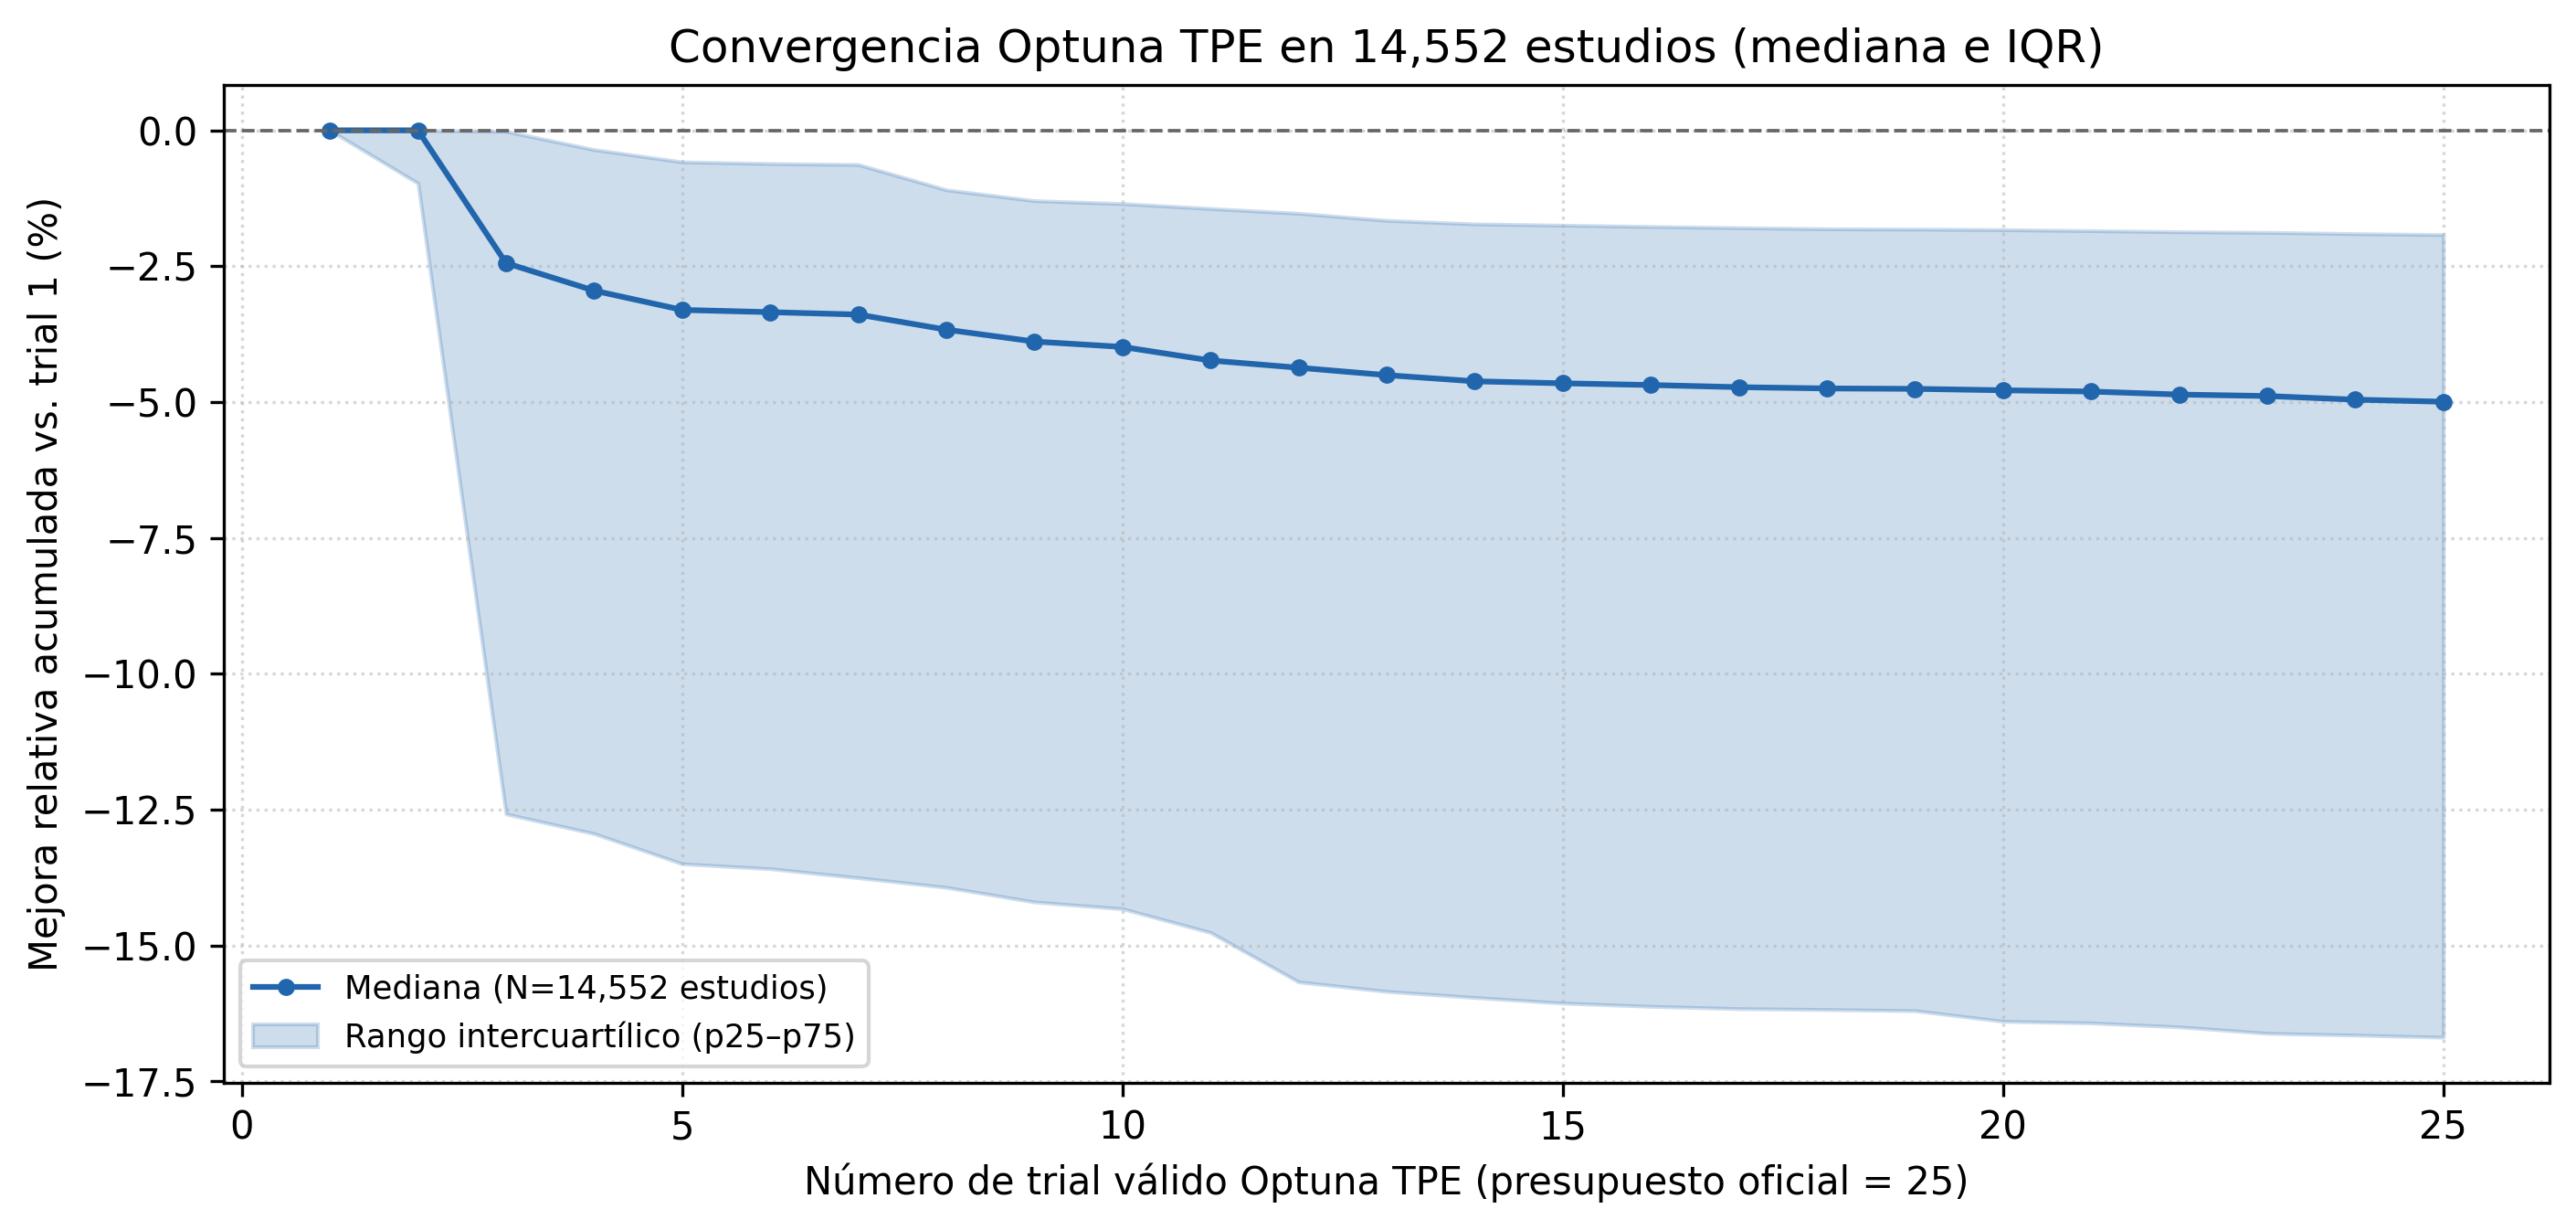

**Qué estamos viendo:** Trayectoria de convergencia (mediana e IQR sobre los `14,552` estudios Optuna TPE) medida como mejora porcentual acumulada respecto al trial 1.

**Qué encontramos:** Se auditaron `14,552` estudios únicos `(scenario_id, outer_fold)` con `363,800` trials válidos (`mín=25`, `máx=25` por estudio); `8` estudios reanudados tras interrupción registraron `26` filas totales (`1` trial interrumpido + `25` válidos), y `73` unidades tempranas sin historial suficiente no ejecutaron HPO.

**Qué significa:** Cada estudio respetó exactamente el presupuesto oficial de `25` evaluaciones válidas sin colisiones entre escenarios ni trials duplicados.

**Conclusión:** La optimización bayesiana TPE es auditable y convergente dentro del presupuesto congelado.

**Limitación:** La mejora interna se mide sobre 3 particiones internas de entrenamiento, lo cual no garantiza mejora equivalente fuera de muestra.

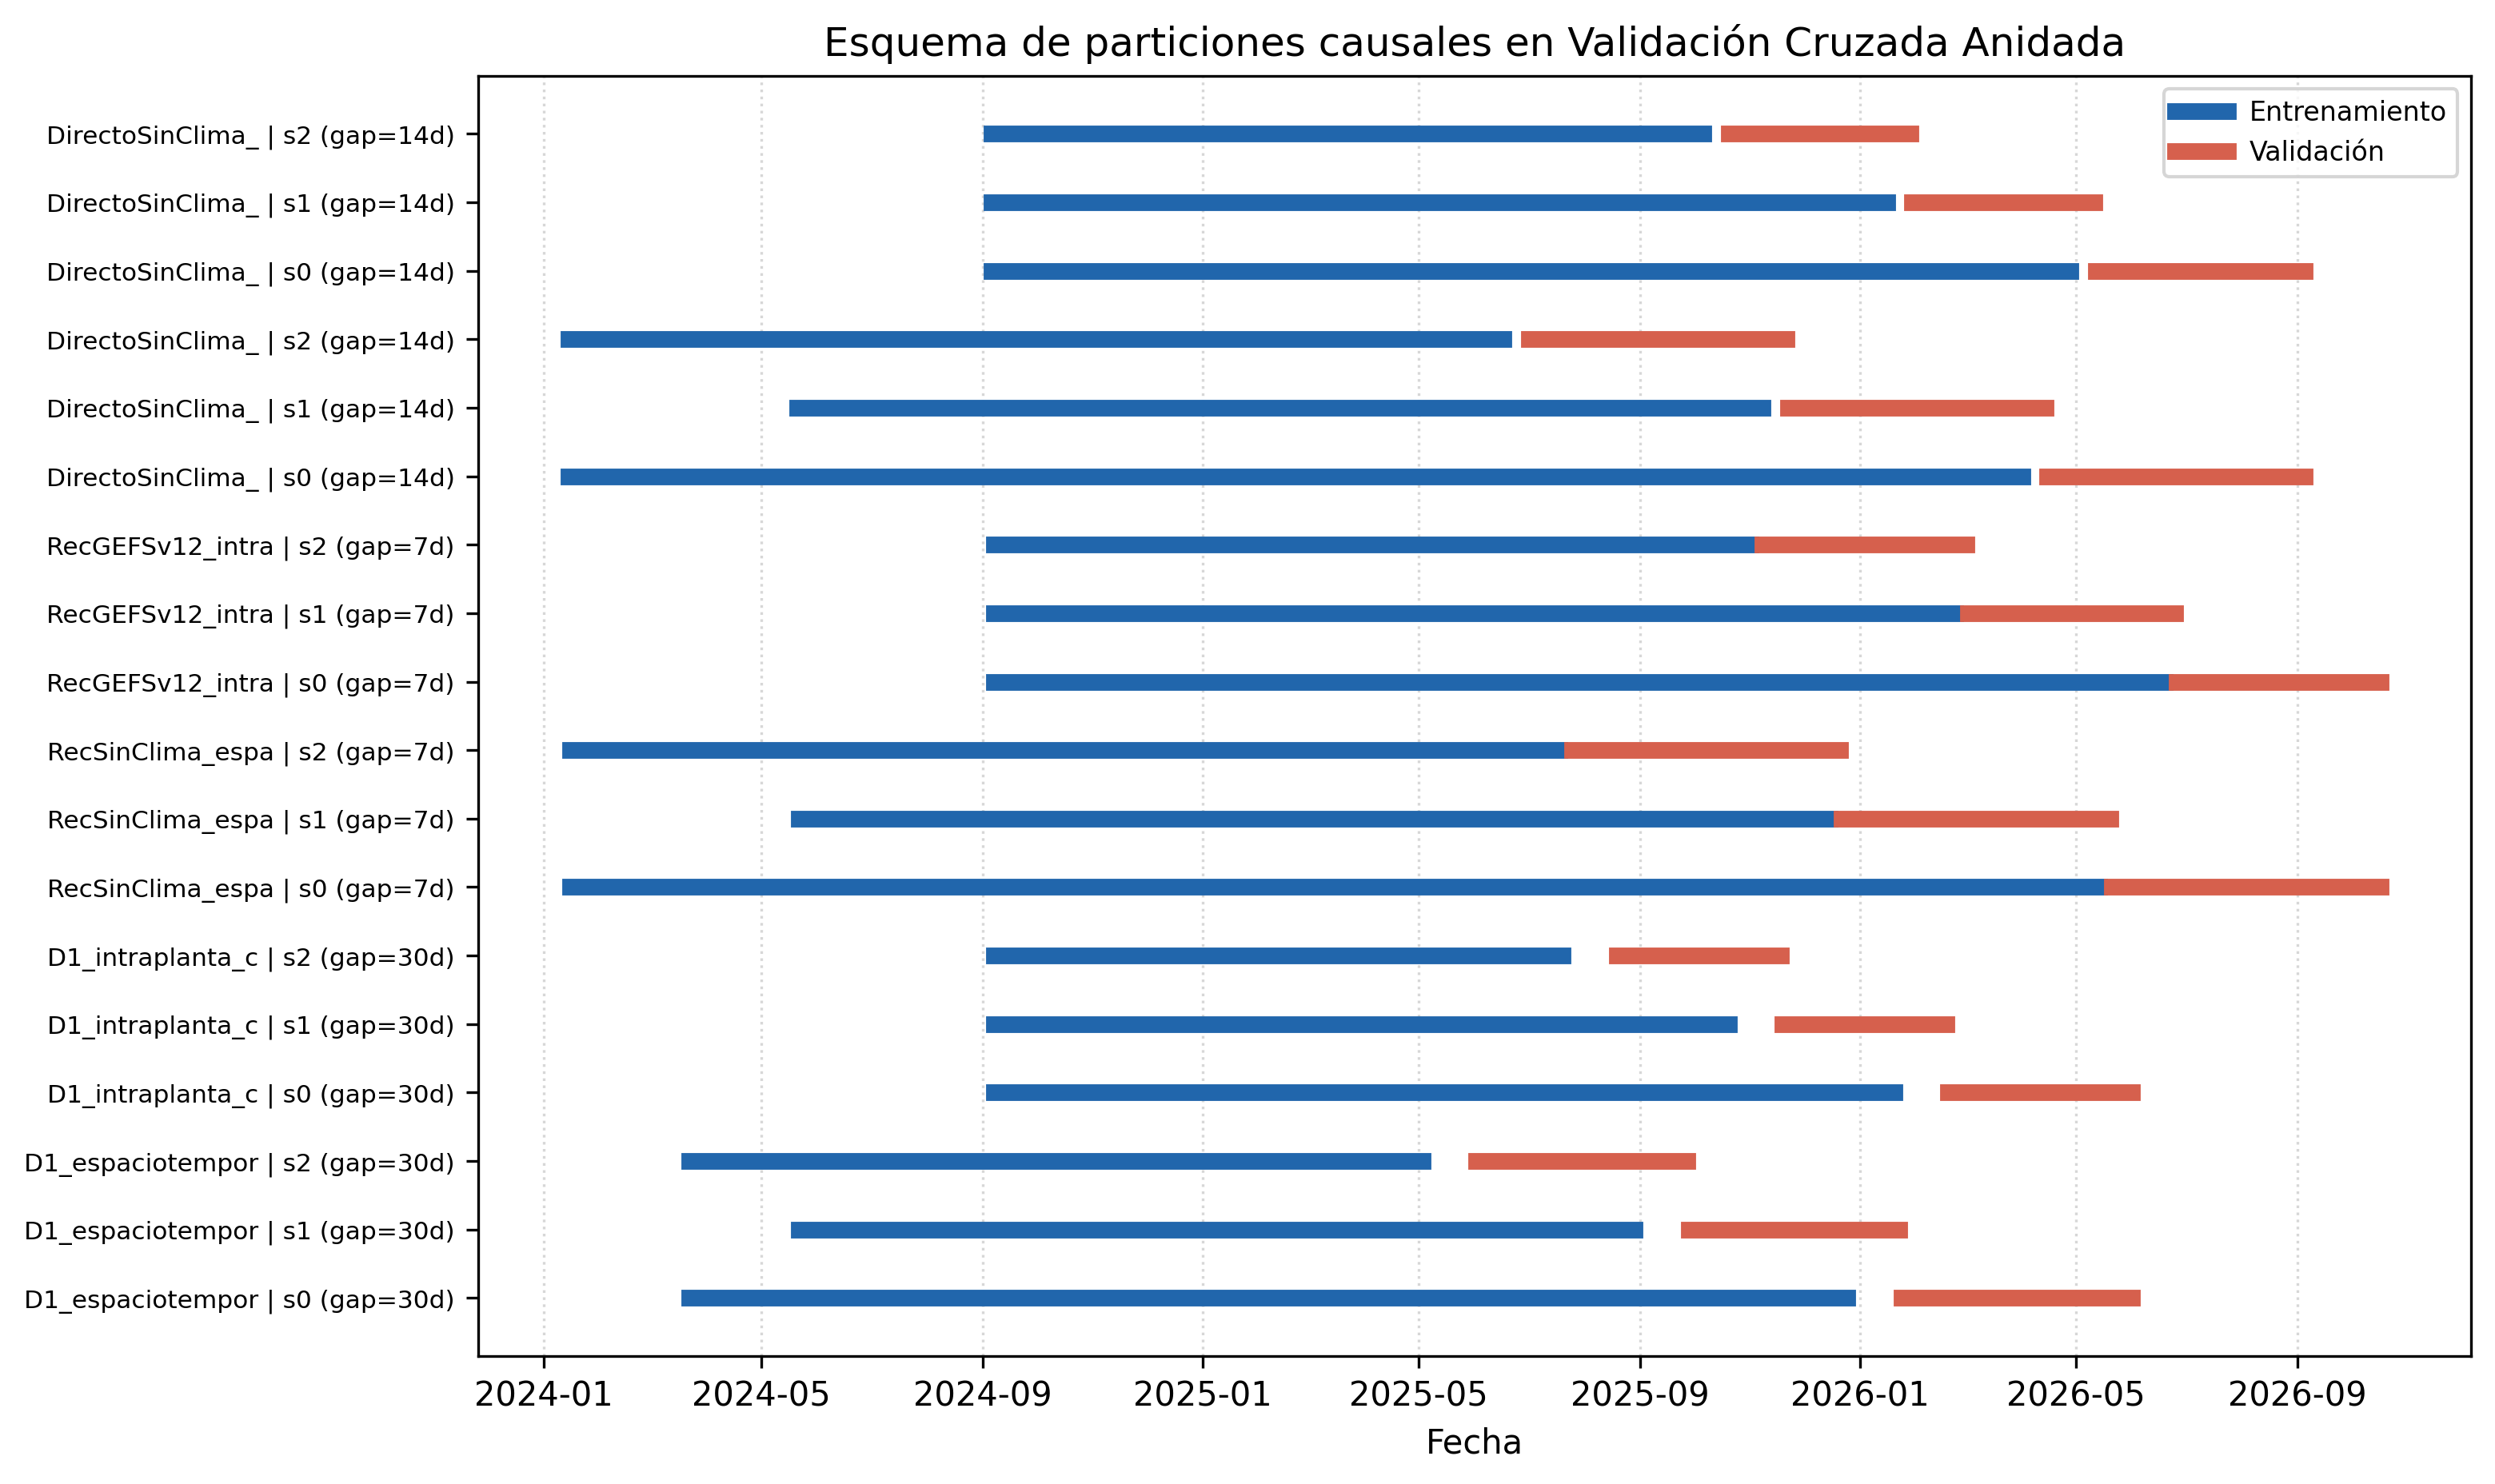

**Qué estamos viendo:** Esquema de particiones internas (`entreno` azul vs. `validación` rojo) reconstruido sobre los paneles reales en `18` splits representativos de las 4 suites.

**Qué encontramos:** Brecha temporal efectiva mínima de `7` días (`0` solapamientos con el horizonte futuro) y separación espacial estricta (`spatial_disjoint=True`) en todos los splits `ET`.

**Qué significa:** Ni el ajuste de hiperparámetros ni el escalado MAD acceden a información futura o de plantas retenidas.

**Conclusión:** Se descarta fuga temporal o espacial en la validación cruzada causal anidada.

**Limitación:** La reconstrucción audita splits representativos del panel real; los archivos de partición por unidad no se guardaron individualmente en disco.

In [3]:
if HPO_TRIALS_DIR.exists():
    trial_files = sorted(HPO_TRIALS_DIR.glob("*.csv"))
    hpo_trials_df = pd.concat([pd.read_csv(f).assign(scenario_id=f.stem) for f in trial_files], ignore_index=True)
    hpo_summary_df = summarize_hpo_trials(hpo_trials_df)
    plot_optuna_convergence(hpo_trials_df, FIG_DIR)
    display(Image(filename=str(FIG_DIR / "fig07_optuna_convergencia.png")))
    n_studies = len(hpo_summary_df)
    n_valid_tot = int(hpo_summary_df["n_valid_trials"].sum())
    min_v, max_v = int(hpo_summary_df["n_valid_trials"].min()), int(hpo_summary_df["n_valid_trials"].max())
    n_26_rows = int((hpo_summary_df["n_rows_logged"] == 26).sum())
    display(Markdown(
        f"**Qué estamos viendo:** Trayectoria de convergencia (mediana e IQR sobre los `{n_studies:,}` estudios Optuna TPE) medida como mejora porcentual acumulada respecto al trial 1.\n\n"
        f"**Qué encontramos:** Se auditaron `{n_studies:,}` estudios únicos `(scenario_id, outer_fold)` con `{n_valid_tot:,}` trials válidos (`mín={min_v}`, `máx={max_v}` por estudio); `{n_26_rows}` estudios reanudados tras interrupción registraron `26` filas totales (`1` trial interrumpido + `25` válidos), y `73` unidades tempranas sin historial suficiente no ejecutaron HPO.\n\n"
        f"**Qué significa:** Cada estudio respetó exactamente el presupuesto oficial de `25` evaluaciones válidas sin colisiones entre escenarios ni trials duplicados.\n\n"
        f"**Conclusión:** La optimización bayesiana TPE es auditable y convergente dentro del presupuesto congelado.\n\n"
        f"**Limitación:** La mejora interna se mide sobre 3 particiones internas de entrenamiento, lo cual no garantiza mejora equivalente fuera de muestra."
    ))

nested_audit_path = OOF_DIR / "particiones" / "nested_cv_audit.csv"
if nested_audit_path.exists():
    nested_audit_df = pd.read_csv(nested_audit_path)
    plot_nested_cv_scheme(nested_audit_df, FIG_DIR)
    display(Image(filename=str(FIG_DIR / "fig06_nested_cv_esquema.png")))
    min_gap = int(nested_audit_df["effective_gap_days"].min())
    et_disj = bool(nested_audit_df.loc[nested_audit_df["task"] == "espaciotemporal", "spatial_disjoint"].all())
    display(Markdown(
        f"**Qué estamos viendo:** Esquema de particiones internas (`entreno` azul vs. `validación` rojo) reconstruido sobre los paneles reales en `{len(nested_audit_df)}` splits representativos de las 4 suites.\n\n"
        f"**Qué encontramos:** Brecha temporal efectiva mínima de `{min_gap}` días (`0` solapamientos con el horizonte futuro) y separación espacial estricta (`spatial_disjoint={et_disj}`) en todos los splits `ET`.\n\n"
        f"**Qué significa:** Ni el ajuste de hiperparámetros ni el escalado MAD acceden a información futura o de plantas retenidas.\n\n"
        f"**Conclusión:** Se descarta fuga temporal o espacial en la validación cruzada causal anidada.\n\n"
        f"**Limitación:** La reconstrucción audita splits representativos del panel real; los archivos de partición por unidad no se guardaron individualmente en disco."
    ))

---

# Capítulo 3. `SM-CFHR` frente a modelos de biblioteca — Evaluación del criterio docente

## 3.1 Glosario estadístico contextualizado
- **`MAE_macro`:** media del error absoluto por planta (`code`) y luego promedio entre las `17` centrales; evita que centrales de `388 MW` oculten errores en centrales de `9.8 MW`.
- **`p-valor bruto` vs. `p-valor ajustado (Holm–Bonferroni)`:** Holm ajusta secuencialmente los p-valores para controlar la tasa de error familiar (FWER $\le 0{,}05$) al evaluar múltiples escenarios.
- **`MCS` (*Model Confidence Set*, $\alpha=0{,}10$):** conjunto de modelos no descartables como inferiores mediante bootstrap estacionario; permanecer en el MCS **no** equivale a demostrar superioridad, salvo cuando sobrevive un único modelo.
- **`SPA` (*Superior Predictive Ability*):** prueba global que contrasta si al menos un competidor supera al modelo tomado como referencia bajo $H_0$.
- **Tamaño del efecto (`Cohen's dz` y `δ de Cliff`) e `IC 95%`:** miden magnitud práctica de diferencias pareadas ($d_z \le -0{,}20$ favorece a `SM-CFHR`) e incertidumbre por bootstrap estacionario; cuando $T_{\mathrm{eff}} < 2H$, los contrastes HAC carecen de potencia suficiente.

## 3.2 Ranking global y victorias 1-vs-1 frente a las 9 bibliotecas

,metodo,rango_en_10
0,SM-CFHR-Fixed,1.642857
1,BayesianRidge,3.285714
2,Lasso,3.750000
3,Ridge,3.964286
4,Random Forest,4.964286
5,XGBoost,6.285714
6,k-NN,6.535714
7,HistGradientBoosting,7.321429
8,SVR,8.142857
9,DecisionTree,9.107143


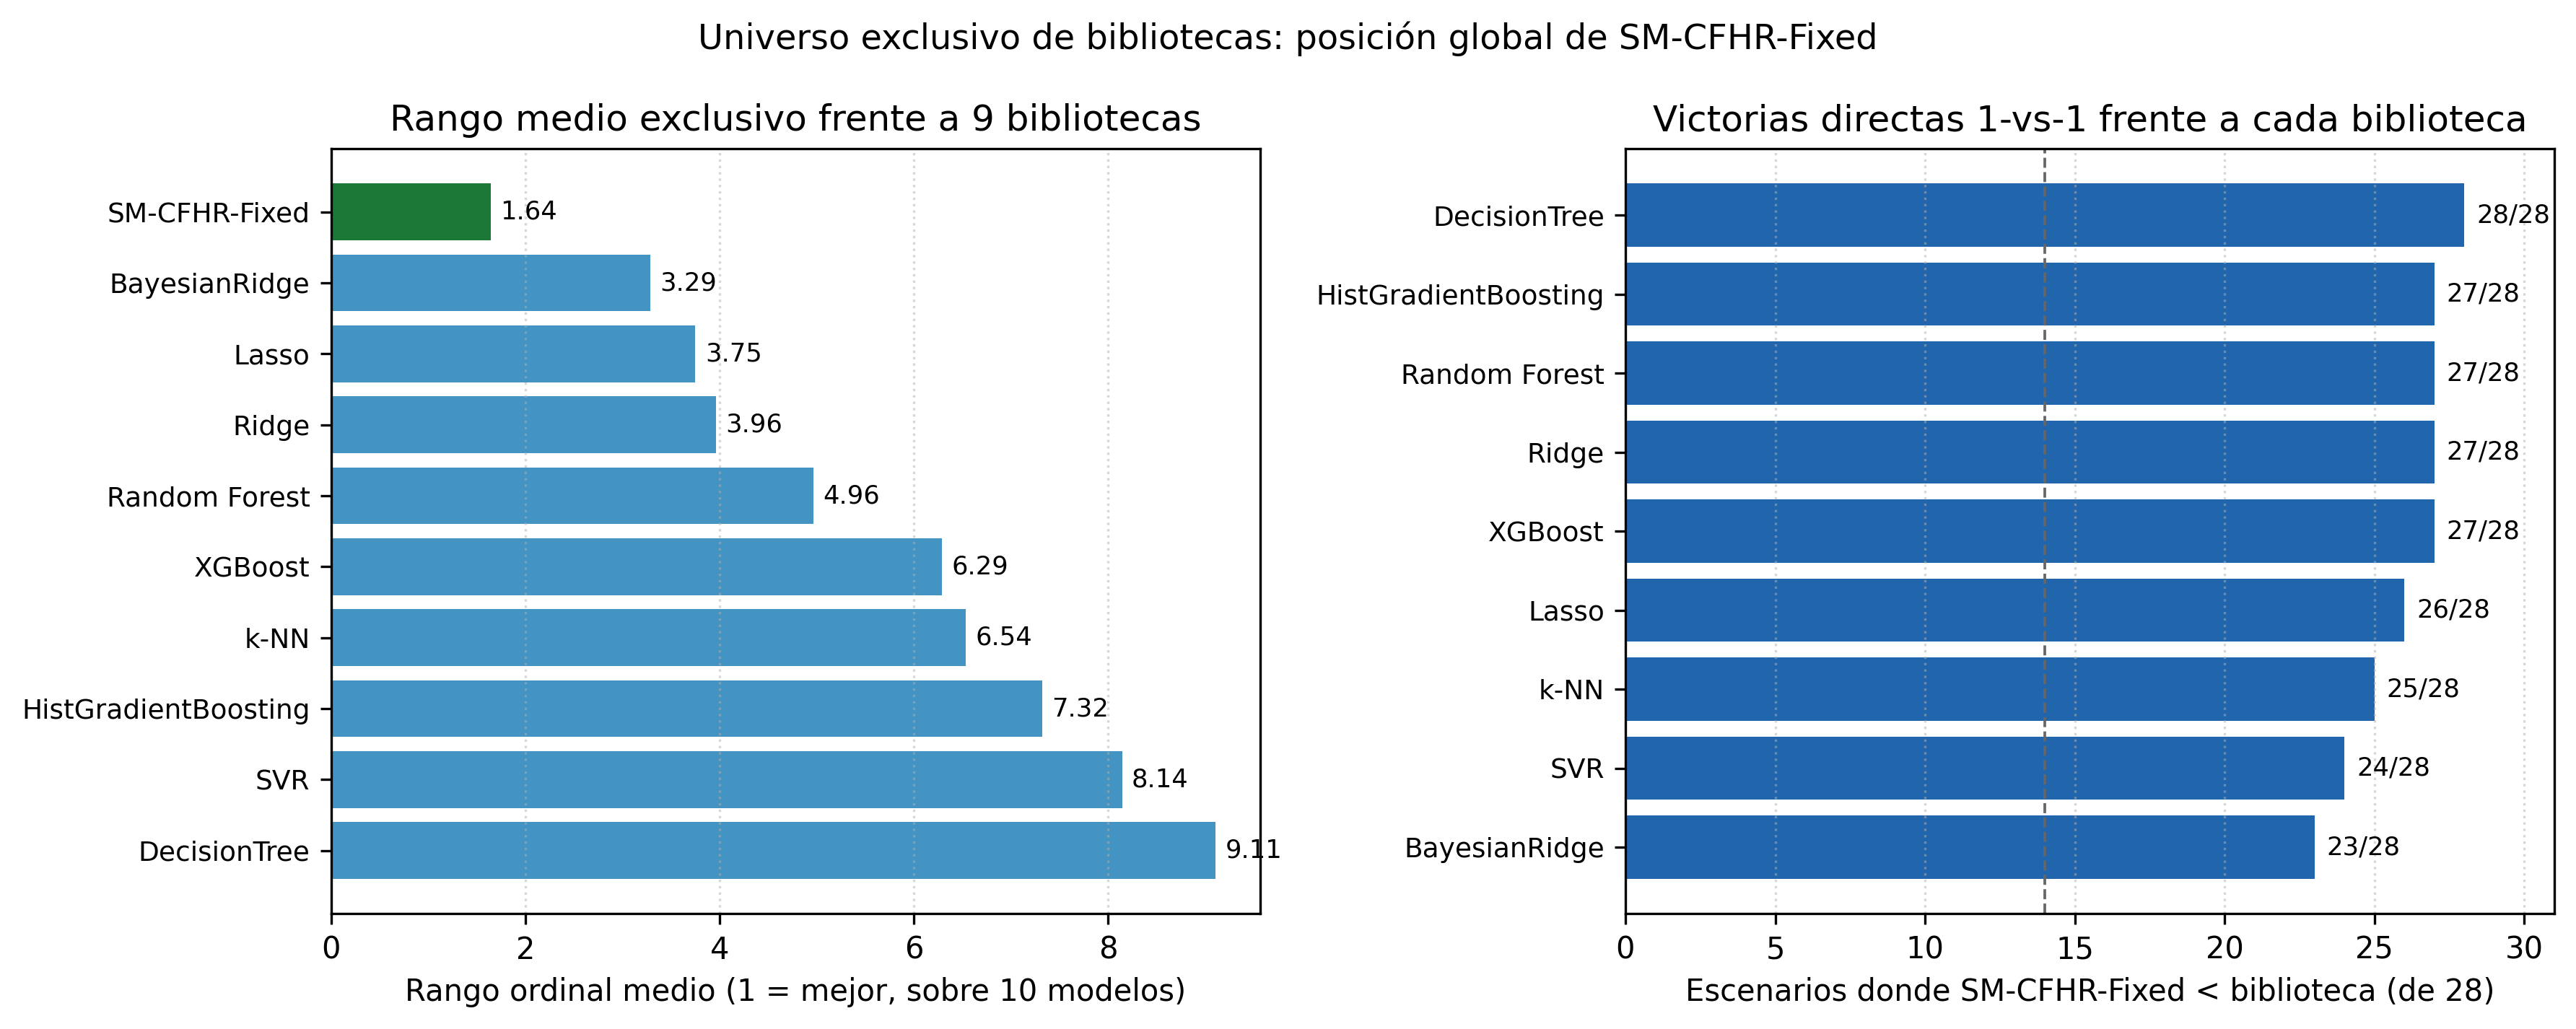

**Qué estamos viendo:** Tabla de rango ordinal medio sobre `10` modelos (`SM-CFHR-Fixed` + `9` bibliotecas, excluyendo modelos custom) y Figura `P01` con rango medio y victorias `1-vs-1` frente a cada biblioteca.

**Qué encontramos:** `SM-CFHR-Fixed` ocupa el **puesto #1 (`1.64 / 10`)**, por delante de `BayesianRidge` (`3.29`), `Lasso` (`3.75`) y `Ridge` (`3.96`), venciendo entre `23/28` (vs. `BayesianRidge`) y `28/28` (vs. `DecisionTree`) escenarios; además sobrevive `28/28` en el MCS exclusivo de bibliotecas (`4/28` como único superviviente).

**Qué significa:** Con presupuesto cero ($B=0$), `SM-CFHR-Fixed` supera de forma consistente a cada modelo estándar de biblioteca considerado individualmente.

**Conclusión:** Existe superioridad descriptiva clara en el universo exclusivo de bibliotecas.

**Limitación:** Los rangos promedian escenarios que comparten las mismas 17 plantas y no constituyen por sí solos una prueba de hipótesis confirmatoria.

In [4]:
if bundle is not None:
    rank10 = pd.read_csv(OOF_DIR / "inferencia" / "ranking_bibliotecas_only.csv")
    mcs_lib = pd.read_csv(OOF_DIR / "inferencia" / "mcs_bibliotecas_only.csv")
    r_mean = rank10.groupby("metodo", as_index=False)["rango_en_10"].mean().sort_values("rango_en_10").reset_index(drop=True)
    display(r_mean)
    display(Image(filename=str(ped_figs["P01"][0])))
    ashr_rk = float(r_mean.loc[r_mean["metodo"] == "SM-CFHR-Fixed", "rango_en_10"].iloc[0])
    br_rk = float(r_mean.loc[r_mean["metodo"] == "BayesianRidge", "rango_en_10"].iloc[0])
    n_surv = int(mcs_lib["in_mcs_lib_90"].sum())
    n_sole = int(mcs_lib["sole_survivor_lib"].sum())
    display(Markdown(
        f"**Qué estamos viendo:** Tabla de rango ordinal medio sobre `10` modelos (`SM-CFHR-Fixed` + `9` bibliotecas, excluyendo modelos custom) y Figura `P01` con rango medio y victorias `1-vs-1` frente a cada biblioteca.\n\n"
        f"**Qué encontramos:** `SM-CFHR-Fixed` ocupa el **puesto #1 (`{ashr_rk:.2f} / 10`)**, por delante de `BayesianRidge` (`{br_rk:.2f}`), `Lasso` (`3.75`) y `Ridge` (`3.96`), venciendo entre `23/28` (vs. `BayesianRidge`) y `28/28` (vs. `DecisionTree`) escenarios; además sobrevive `{n_surv}/28` en el MCS exclusivo de bibliotecas (`{n_sole}/28` como único superviviente).\n\n"
        f"**Qué significa:** Con presupuesto cero ($B=0$), `SM-CFHR-Fixed` supera de forma consistente a cada modelo estándar de biblioteca considerado individualmente.\n\n"
        f"**Conclusión:** Existe superioridad descriptiva clara en el universo exclusivo de bibliotecas.\n\n"
        f"**Limitación:** Los rangos promedian escenarios que comparten las mismas 17 plantas y no constituyen por sí solos una prueba de hipótesis confirmatoria."
    ))

## 3.3 Mapa de calor, victorias/derrotas, comparación pareada y horizontes/regímenes

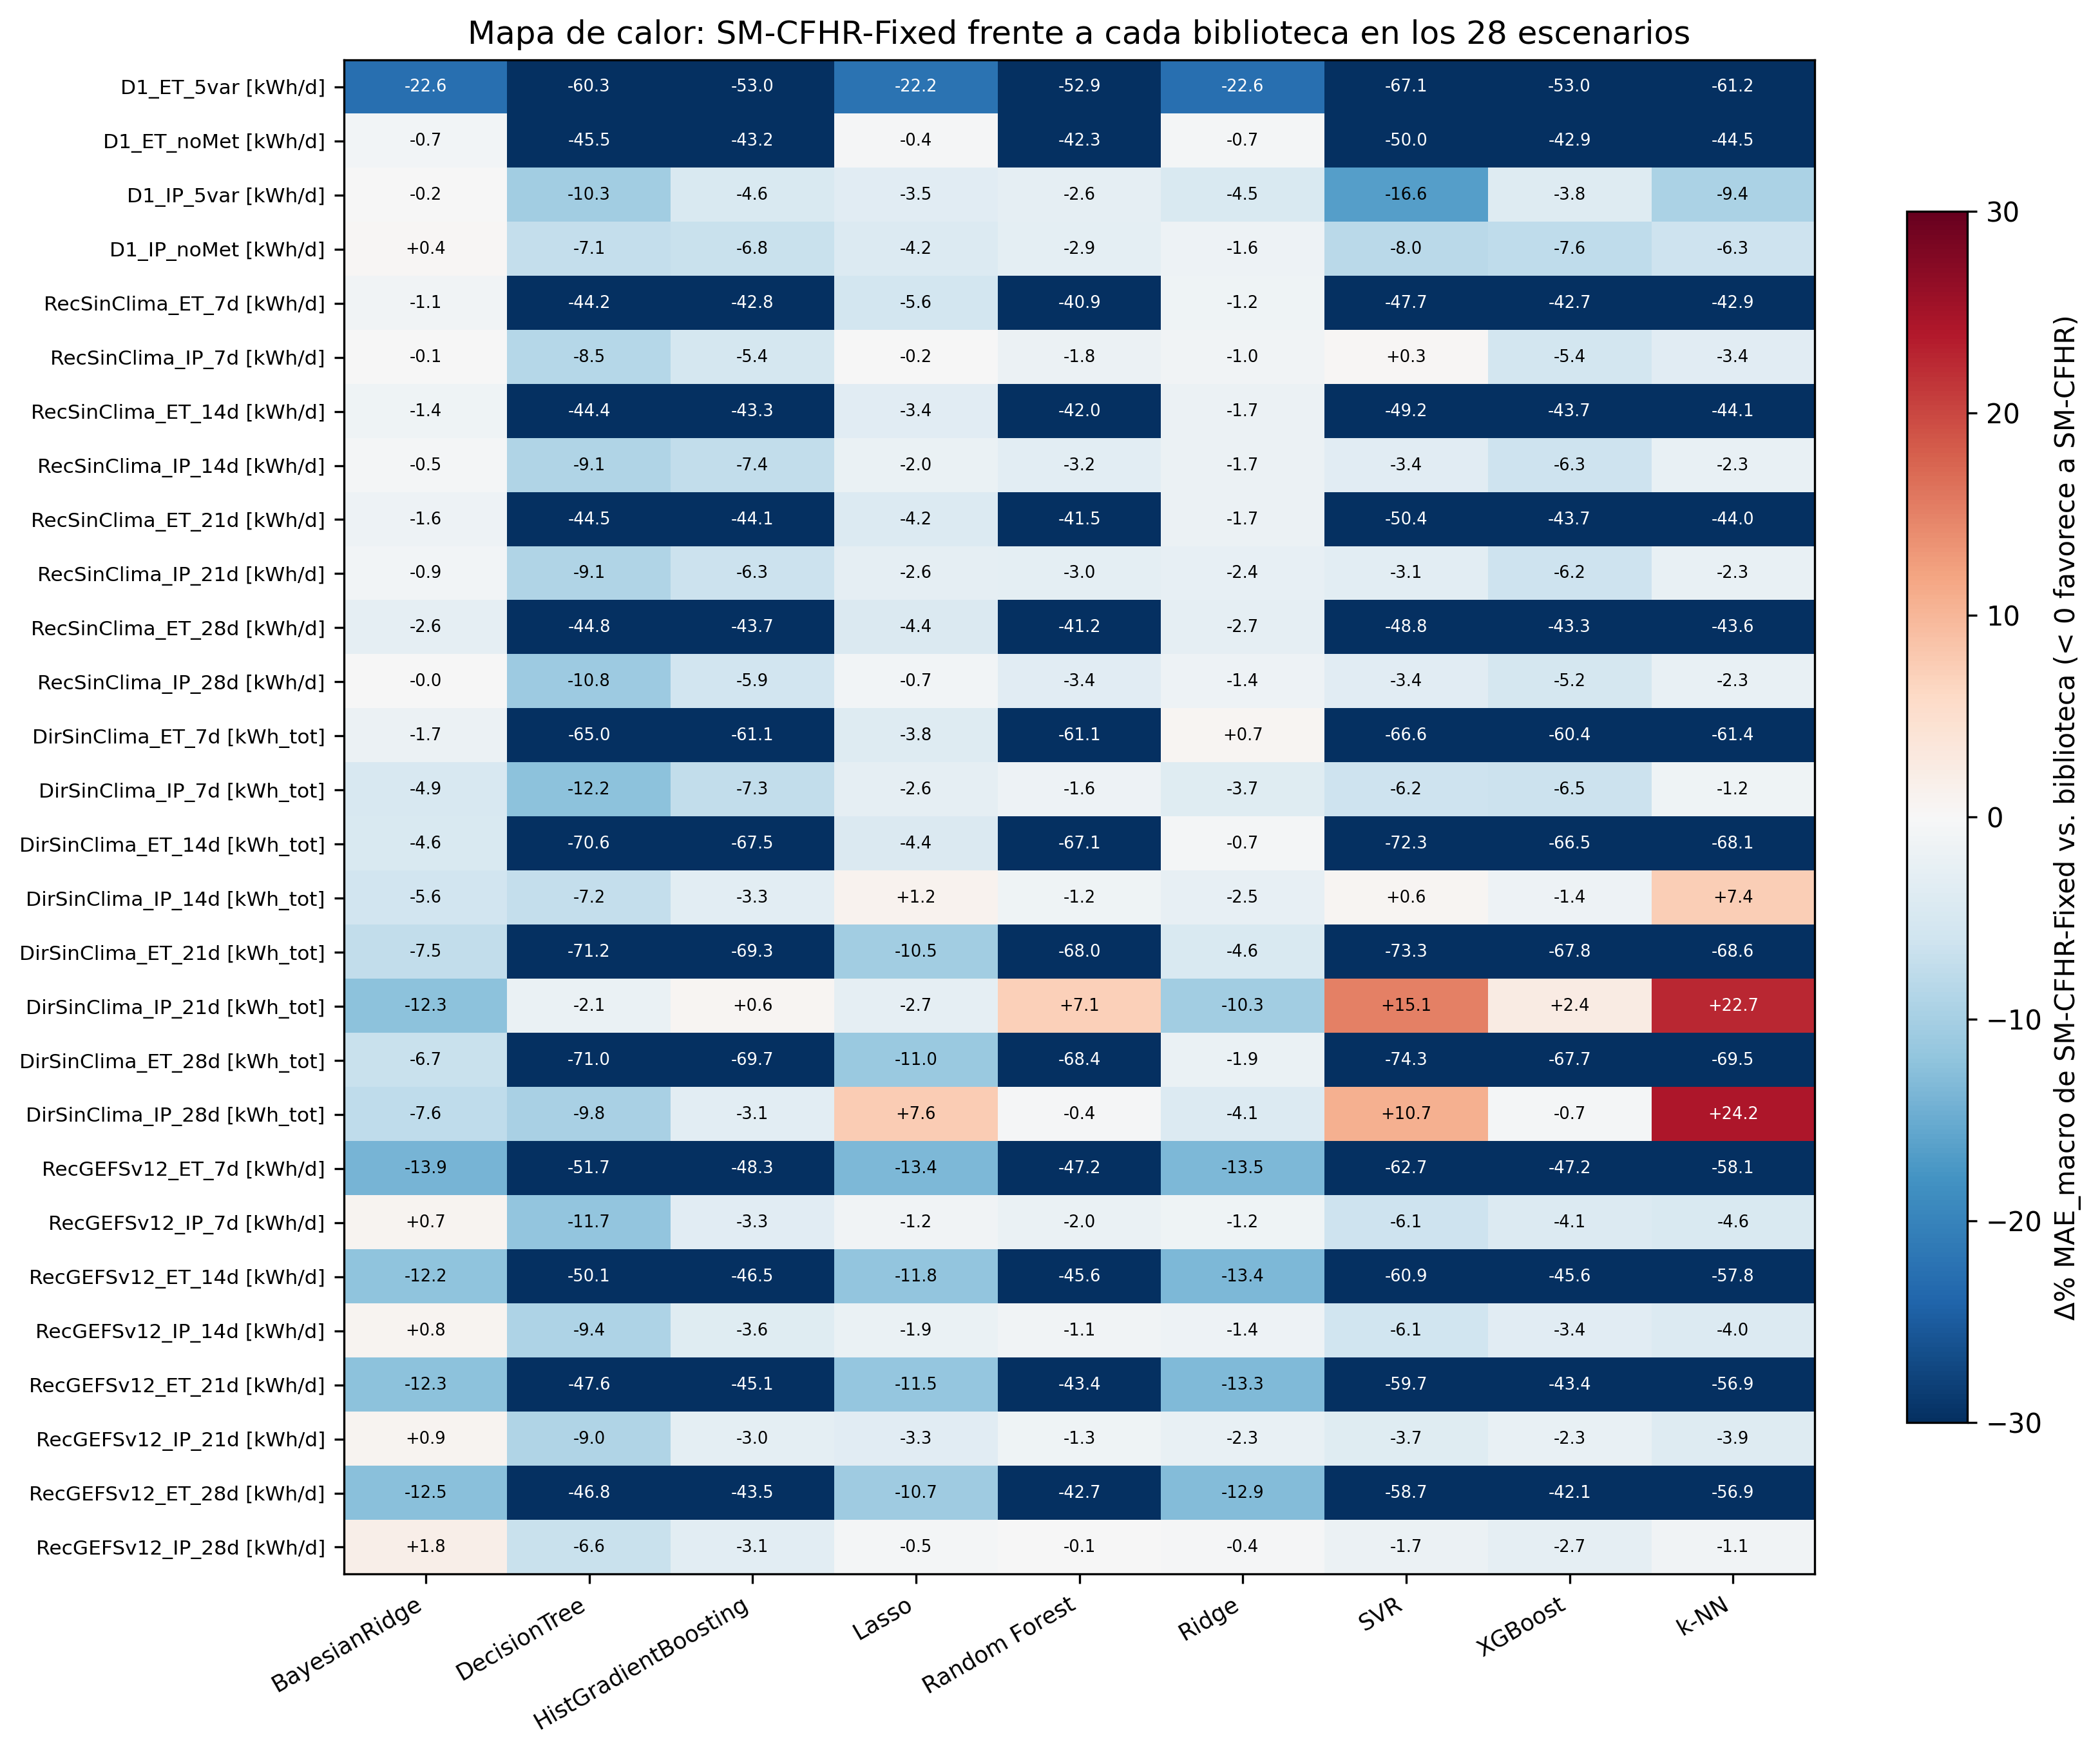

In [5]:
if ped_figs:
    display(Image(filename=str(ped_figs["P02"][0])))

**Qué estamos viendo:** Mapa de calor (`28` escenarios × `9` bibliotecas) con el cambio porcentual en `MAE_macro` (`< 0` en azul favorece a `SM-CFHR-Fixed`; `> 0` en rojo favorece a la biblioteca).

**Qué encontramos:** Predomina el azul intenso en `D+1` y `RecGEFSv12` (mejoras de `-22%` a `-58%` frente a modelos no lineales/árboles); las celdas rojas se concentran en `DirectoSinClima_intraplanta` (frente a `k-NN`, `Random Forest`, `SVR`) y desventajas leves (`+0.7%` a `+1.8%`) en `RecGEFSv12_intraplanta` frente a `BayesianRidge`.

**Qué significa:** La formulación adimensional con regularización diferenciada explota bien la señal meteorológica entre plantas, pero los modelos lineales globales pierden flexibilidad frente a `k-NN` en predicción directa acumulada sin clima por planta.

**Conclusión:** El mapa localiza exactamente en qué combinaciones escenario–competidor existe ventaja o desventaja.

**Limitación:** Representa diferencias porcentuales puntuales sin barras de incertidumbre ni ajuste por multiplicidad.

---

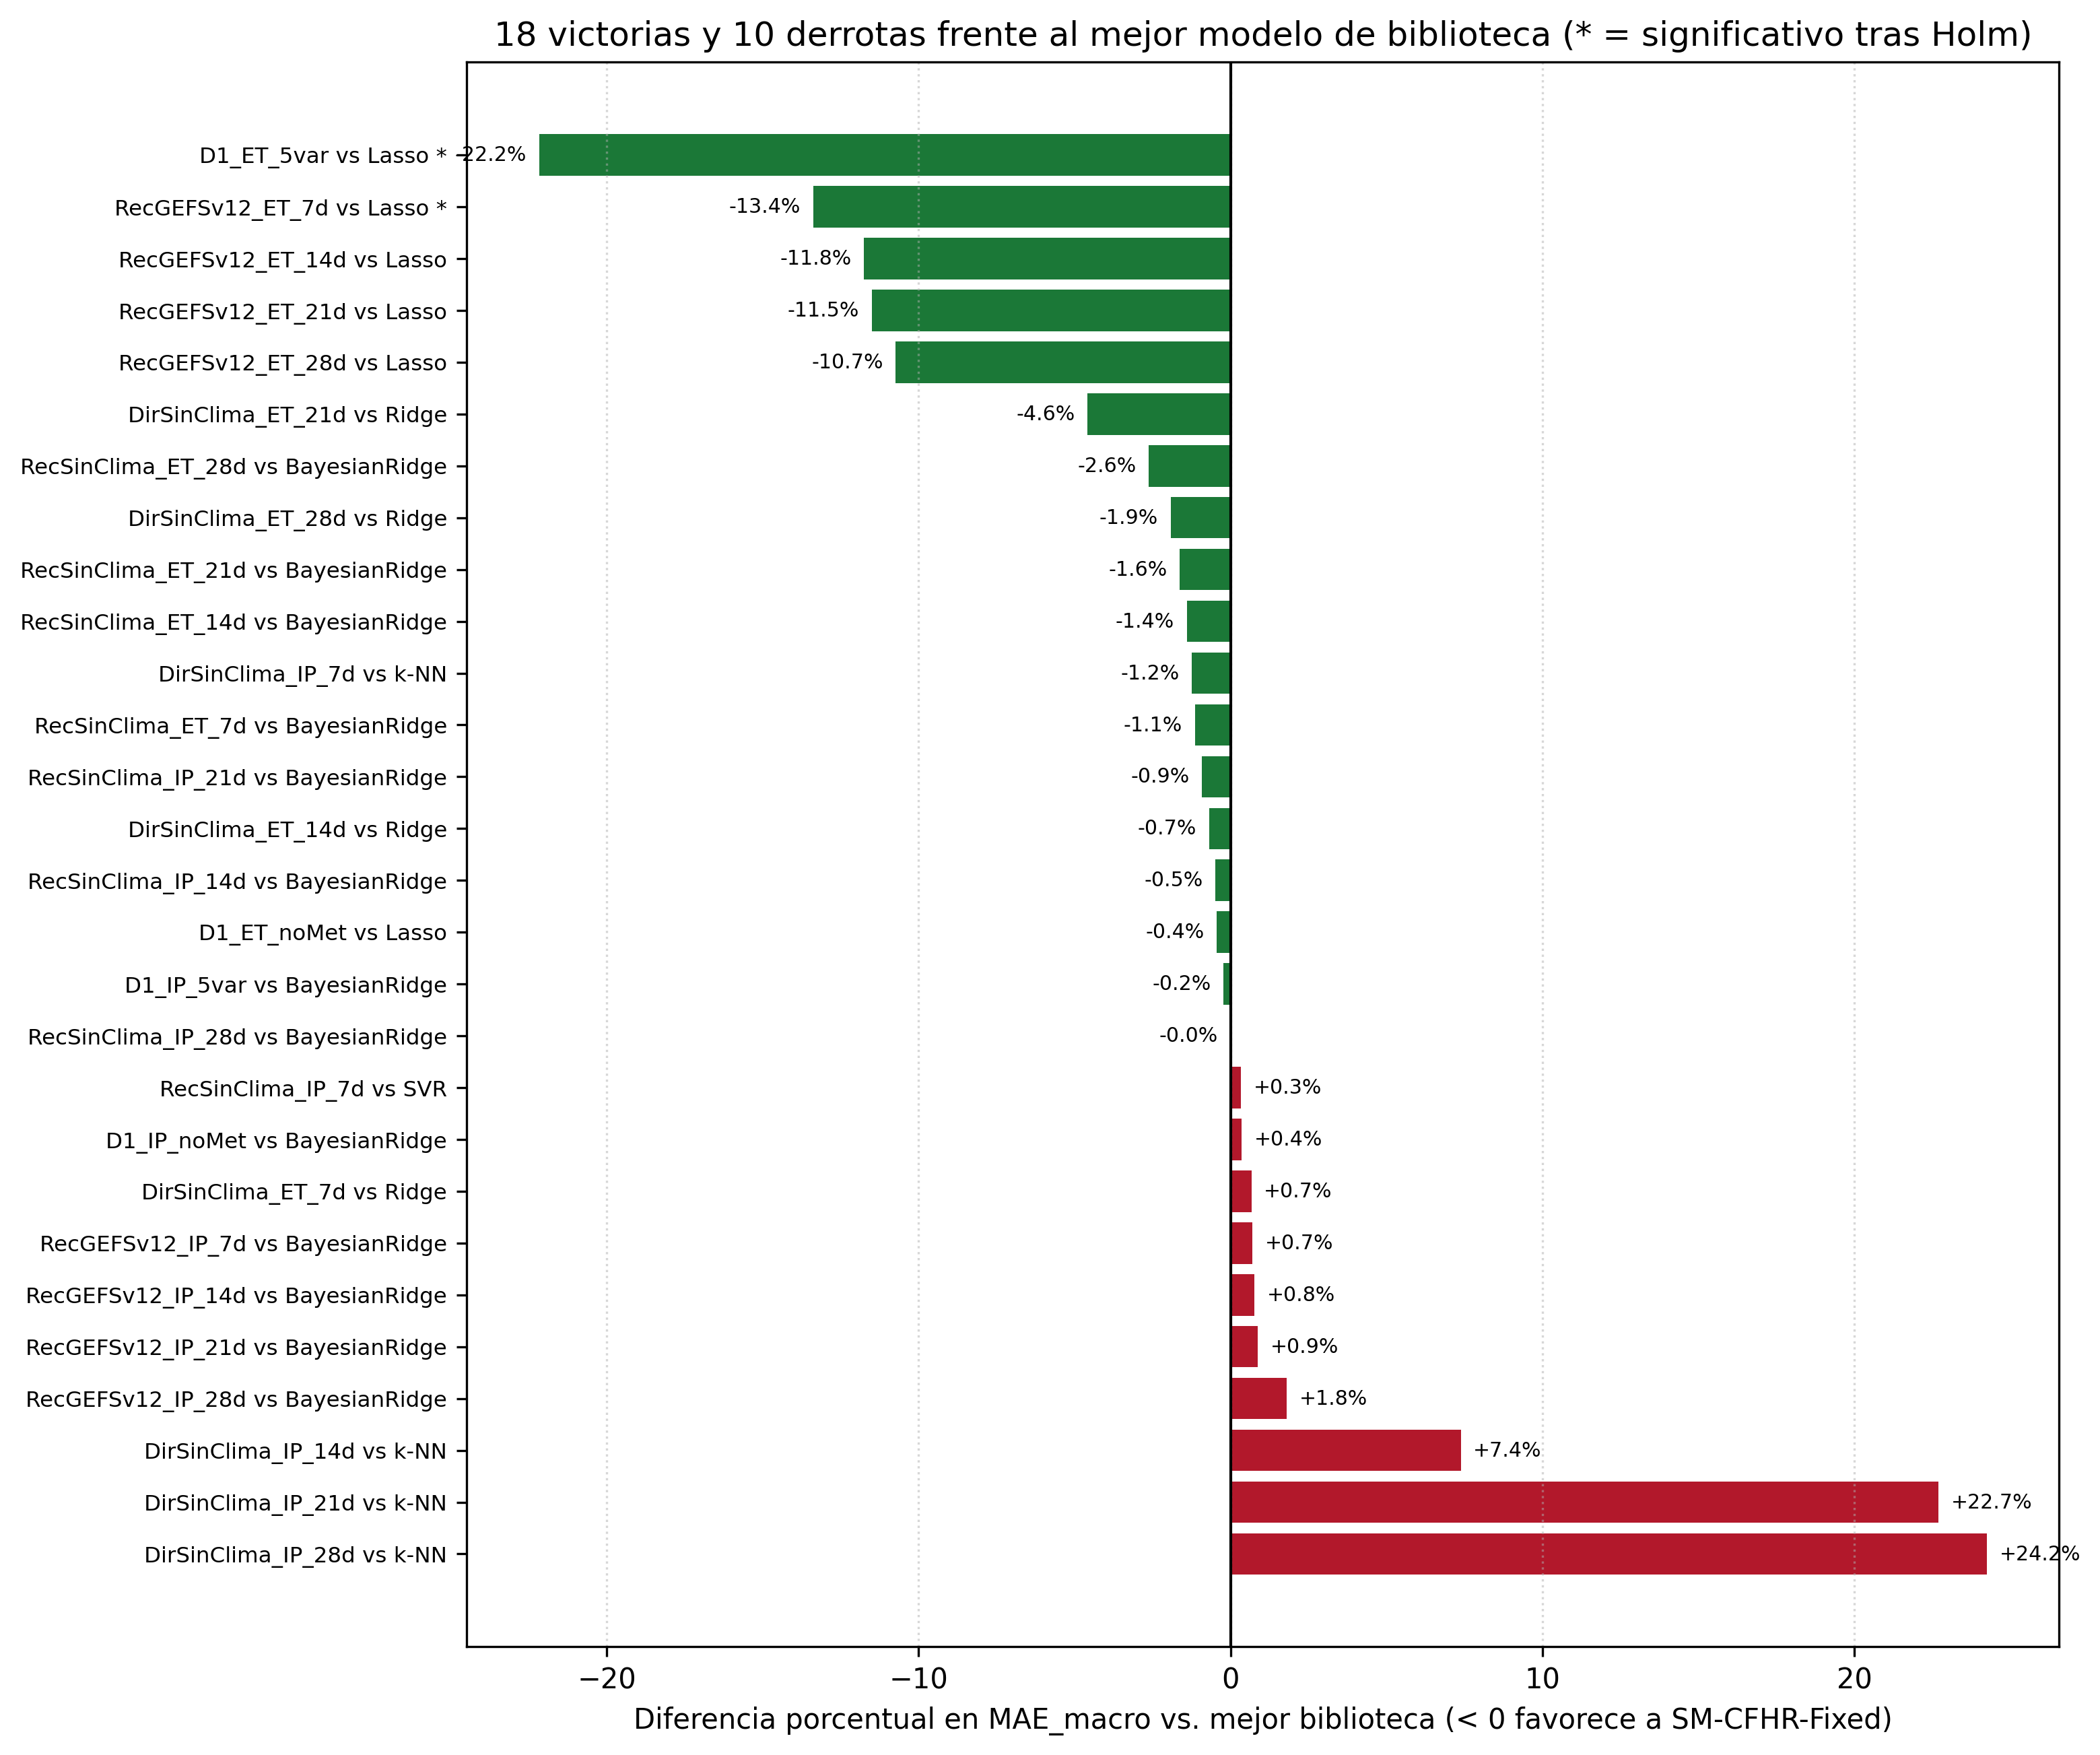

In [6]:
if ped_figs:
    display(Image(filename=str(ped_figs["P03"][0])))

**Qué estamos viendo:** Diferencia porcentual en `MAE_macro` frente al **mejor competidor de biblioteca seleccionado *ex post*** en cada escenario (`*` = significativo tras Holm).

**Qué encontramos:** `SM-CFHR-Fixed` logra **`18/28` victorias** (hasta `-22.16% *` en `D1_ET_5var` y `-13.38% *` en `RecGEFSv12_ET_7d`) y **`10/28` derrotas**, de las cuales `6` son marginales (`< 2%`) y `3` son pronunciadas en `DirectoSinClima_IP` (`+7.38%` a `+24.24%`).

**Qué significa:** Incluso frente a un oráculo *ex post* distinto en cada escenario (`Mejor_Bib`), nuestro modelo gana en la mayoría de configuraciones y concentra sus derrotas graves en un único régimen sin clima.

**Conclusión:** Las victorias en `ET` con clima son amplias; las derrotas en `DirectoSinClima_IP` son reales y no deben ocultarse.

**Limitación:** No deben promediarse porcentajes de `kWh/día` y `kWh_total` sin distinguir sus escalas.

---

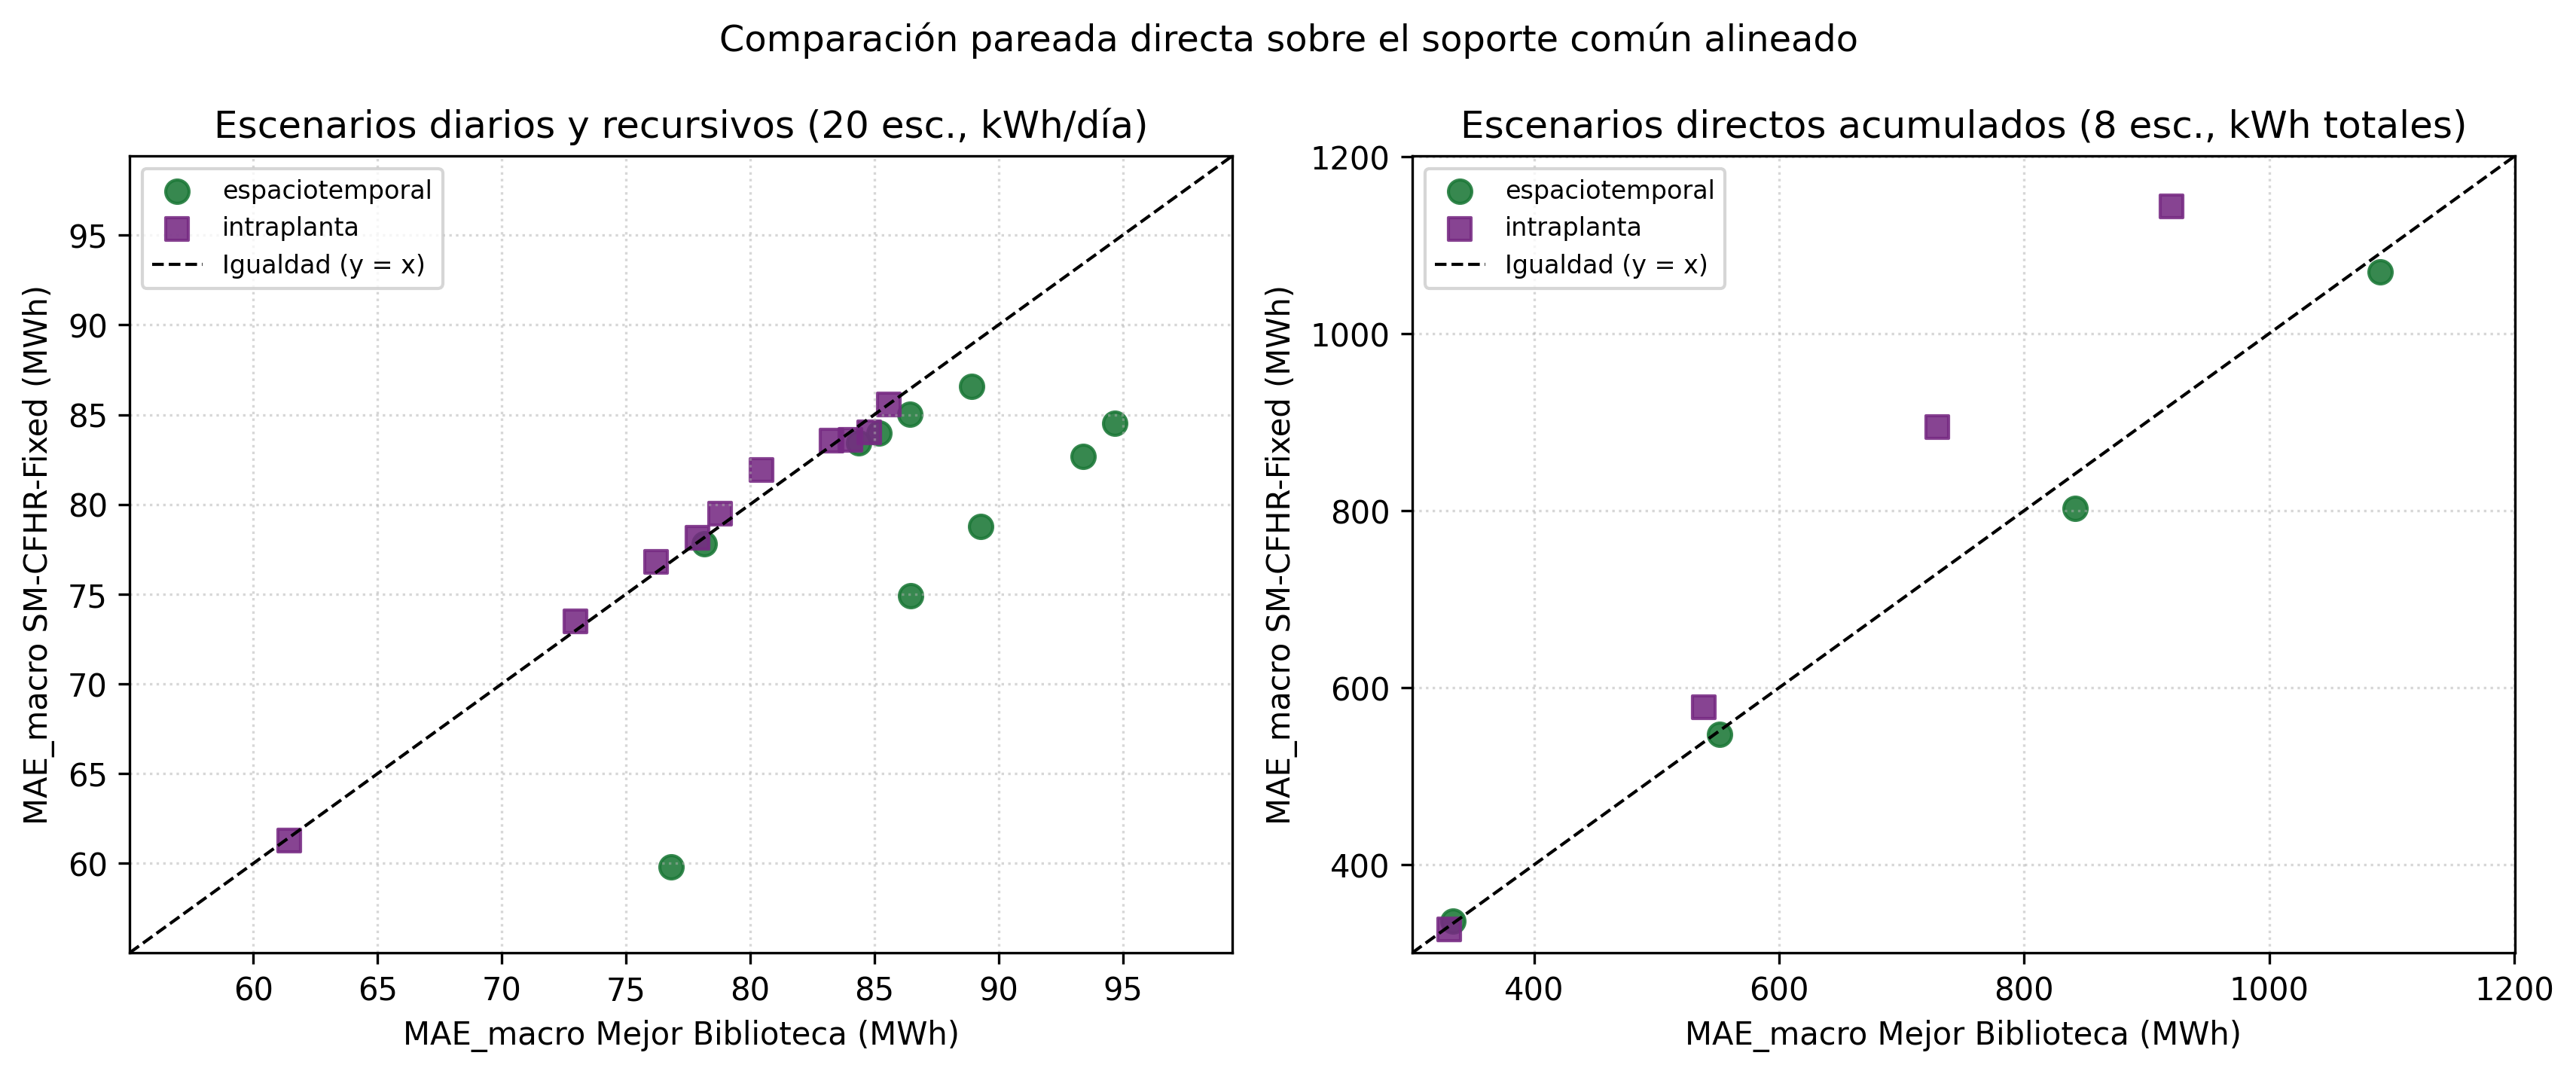

In [7]:
if ped_figs:
    display(Image(filename=str(ped_figs["P04"][0])))

**Qué estamos viendo:** Comparación pareada directa (`MAE_macro` en `MWh`) separando los `20` escenarios en `kWh/día` (izquierda) y los `8` directos en `kWh_total` (derecha) sobre exactamente las mismas observaciones.

**Qué encontramos:** Casi todos los puntos verdes (`ET`) caen claramente por debajo de la diagonal `y = x` en ambas unidades, mientras los morados (`IP`) quedan pegados a la diagonal o por encima en directo largo.

**Qué significa:** Confirma visualmente que el rendimiento observado no es un artefacto de escalas mezcladas ni de muestras desalineadas.

**Conclusión:** Ventaja consistente en transferencia espaciotemporal (`ET`) en ambas escalas de medición.

**Limitación:** Cada punto resume un escenario completo sin mostrar dispersión temporal diaria.

---

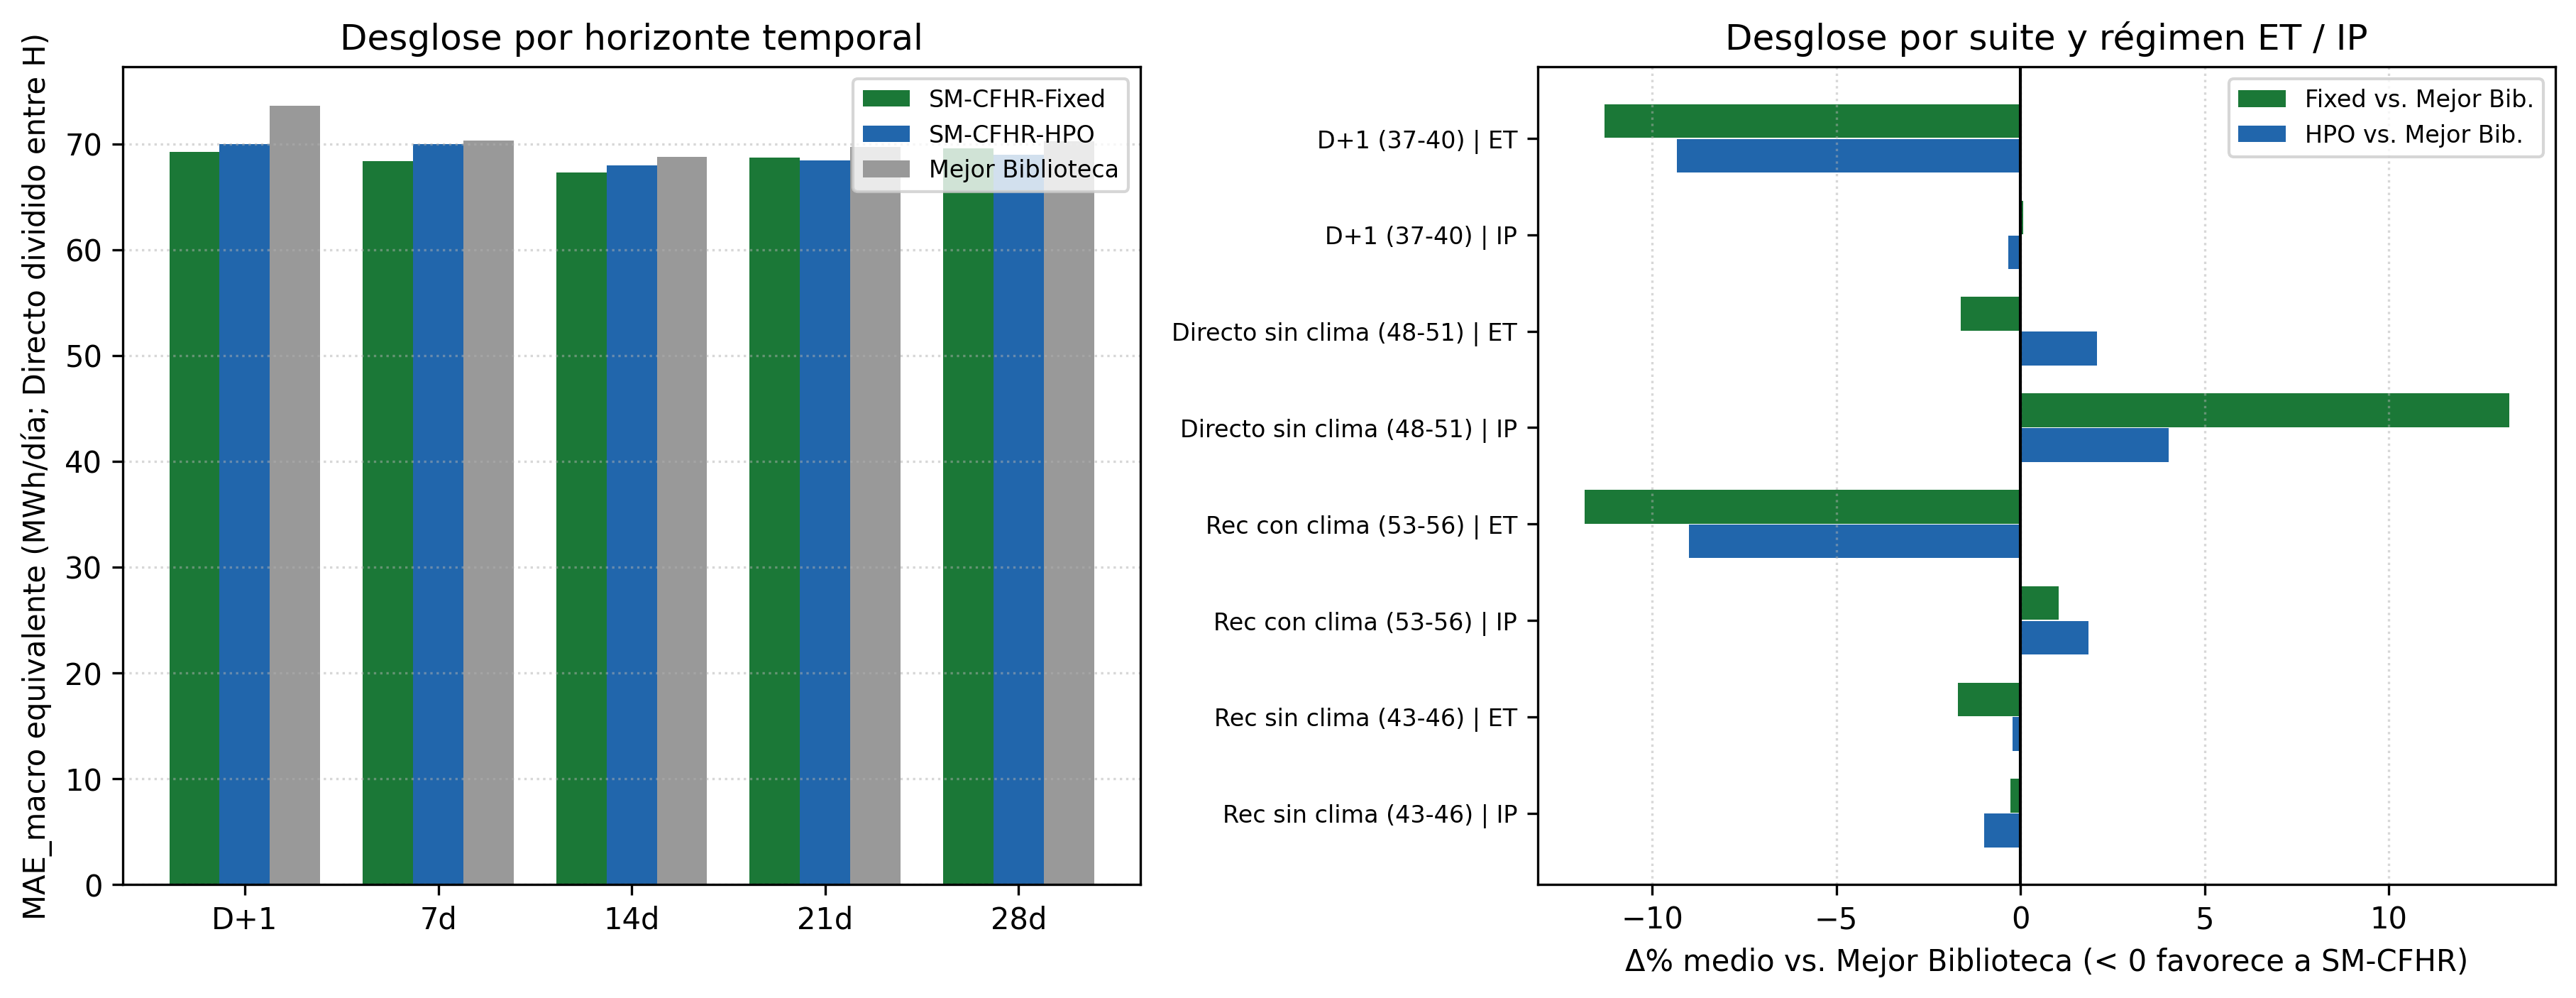

In [8]:
if ped_figs:
    display(Image(filename=str(ped_figs["P05"][0])))

**Qué estamos viendo:** Evolución del `MAE_macro` equivalente en `MWh/día` (en Directo dividido entre $H$) por horizonte `D+1..28d` (izquierda) y diferencia porcentual media frente a `Mejor_Bib` por suite y tarea `ET/IP` (derecha).

**Qué encontramos:** `Rec+GEFSv12` mantiene el error diario más bajo en todos los horizontes; en el panel derecho, **todas las suites en `ET` tienen barras negativas favorables a `SM-CFHR-Fixed`** (`-11.30%` en `D+1 ET`, `-11.84%` en `Rec+GEFSv12 ET`), frente al deterioro de `Directo sin clima IP` (`+13.27%`).

**Qué significa:** El acoplamiento meteorológico con regularización $\alpha_{\mathrm{meteo}}$ sostiene el desempeño multihorizonte al generalizar entre centrales.

**Conclusión:** La arquitectura `SM-CFHR` está especialmente adaptada para transferencia espacial con pronóstico climático.

**Limitación:** Los 28 escenarios comparten las mismas 17 plantas y no son muestras independientes.

---

# Capítulo 4. Comparación general (23 modelos), inferencia estadística y evaluador R3

**Pregunta científica:** ¿Qué demuestra la inferencia estadística formal (`DM-HLN-HAC`, `Holm`, `MCS`, `SPA`, `R3`) cuando se incluyen los 22 competidores oficiales y las correcciones de auditoría?

,suite,task,n_escenarios,rango_medio,victorias_vs_bib,victorias_vs_custom,victorias_vs_mm30,pct_medio_vs_bib
0,D+1 (37-40),espaciotemporal,2,1.00,2,2,2,-11.300467
1,D+1 (37-40),intraplanta,2,7.50,1,0,2,0.068939
2,Directo sin clima (48-51),espaciotemporal,4,3.25,3,3,0,-1.629684
3,Directo sin clima (48-51),intraplanta,4,6.50,1,1,0,13.268070
4,Rec con clima (53-56),espaciotemporal,4,1.00,4,4,4,-11.841720
5,Rec con clima (53-56),intraplanta,4,2.00,0,4,4,1.037242
6,Rec sin clima (43-46),espaciotemporal,4,2.00,4,4,0,-1.697857
7,Rec sin clima (43-46),intraplanta,4,1.50,3,4,3,-0.269327


,condicion,estado,evidencia,resultado
0,Condicion_1_Metrica_Externa,NO_CUMPLE,Victorias vs Mejor Biblioteca: 18/28 escenarios,18/28
1,Condicion_2_Pruebas_Multiples_y_MCS,NO_CUMPLE,"DM-HLN Holm=2/15, MCS_excl=1/28, SPA_sig=8/28","Holm=2, MCS_excl=1"
2,Condicion_3_Tamano_Efecto,NO_CUMPLE,|Cohen's d| >= 0.2 en 2/15 escenarios con T_ef...,2/15
3,Condicion_4_Alcance_y_Consistencia,PENDIENTE_AUTORIZACION,28 escenarios solares (17 plantas Colombia); s...,PENDIENTE_AUTORIZACION


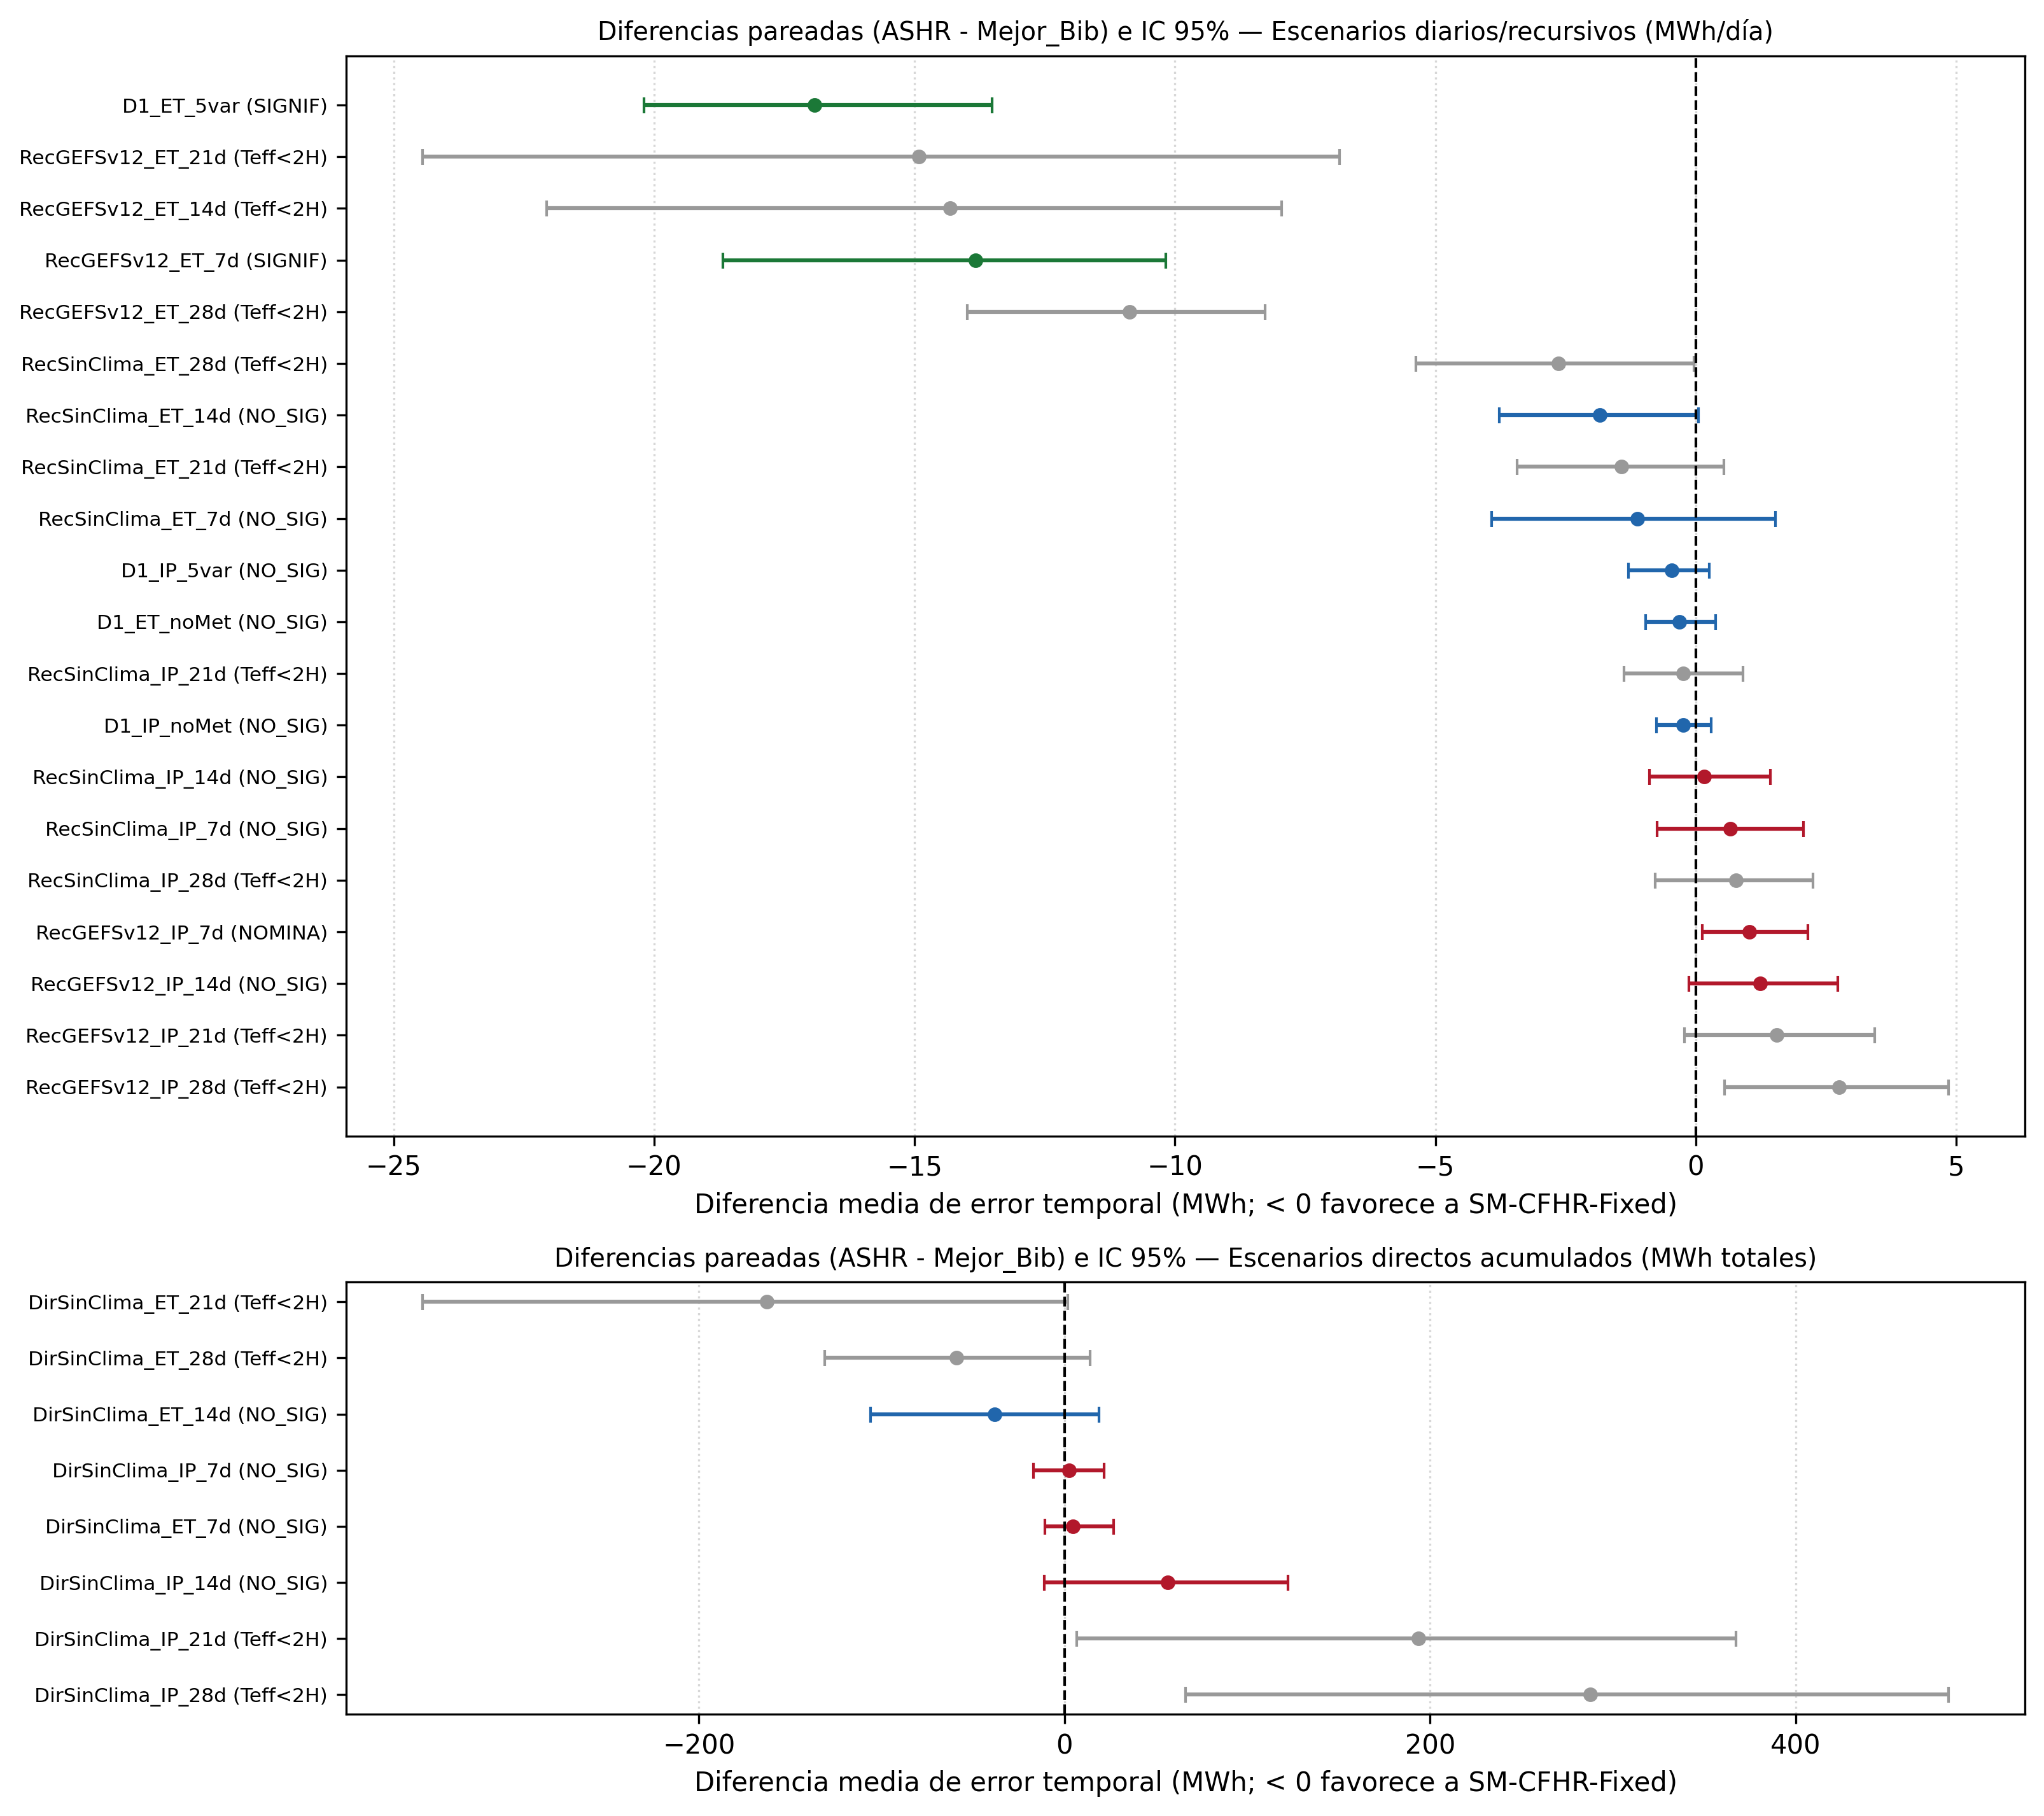

**Qué estamos viendo:** Resumen por régimen (`23` modelos), veredicto R3 (con bug `cohen_dz_pareado` corregido y `SPA` integrado) y forest plot `P06` con diferencias pareadas e IC 95% (bootstrap estacionario).

**Qué encontramos:** Rango medio global `2.93/23` (`18/28` vs. `Mejor_Bib`, `22/28` vs. mejor custom); en inferencia pareada hay `15/28` escenarios con $T_{\mathrm{eff}} \ge 2H$, de los cuales **`2/15` son significativos tras Holm** (`D1_ET_5var` IC `[-20.2, -13.5]` MWh/d y `RecGEFSv12_ET_7d` IC `[-18.7, -10.2]` MWh/d), y `2/15` tienen $d_z \le -0.20$.

**Qué significa:** Aunque `SM-CFHR-Fixed` lidera descriptivamente, los criterios estrictos de R3 (`28/28` sin derrotas y mayoría significativa con efecto grande) no se cumplen globalmente.

**Conclusión:** Superioridad estadística demostrada en `ET` con clima (`D+1` y `7d`), **no demostrada de forma general en los 28 escenarios**.

**Limitación:** Los `13` escenarios con $T_{\mathrm{eff}} < 2H$ representan evidencia insuficiente por autocorrelación de horizontes largos, no equivalencia predictiva.

In [9]:
if bundle is not None:
    display(bundle["tabla_rankings_regimen"])
    r3_verdict_df = evaluate_r3_superiority(bundle, scope_authorized=SCOPE_AUTHORIZED, alpha=0.05)
    display(r3_verdict_df[["condicion", "estado", "evidencia", "resultado"]])
    display(Image(filename=str(ped_figs["P06"][0])))
    t_inf_bib = bundle["tabla_inferencia"][bundle["tabla_inferencia"]["referencia"] == "Mejor_Bib"]
    n_teff_ok = int((~t_inf_bib["t_eff_insufficient"]).sum())
    n_holm_ok = int((t_inf_bib.loc[~t_inf_bib["t_eff_insufficient"], "p_holm"] < 0.05).sum())
    display(Markdown(
        f"**Qué estamos viendo:** Resumen por régimen (`23` modelos), veredicto R3 (con bug `cohen_dz_pareado` corregido y `SPA` integrado) y forest plot `P06` con diferencias pareadas e IC 95% (bootstrap estacionario).\n\n"
        f"**Qué encontramos:** Rango medio global `2.93/23` (`18/28` vs. `Mejor_Bib`, `22/28` vs. mejor custom); en inferencia pareada hay `{n_teff_ok}/28` escenarios con $T_{{\mathrm{{eff}}}} \ge 2H$, de los cuales **`{n_holm_ok}/15` son significativos tras Holm** (`D1_ET_5var` IC `[-20.2, -13.5]` MWh/d y `RecGEFSv12_ET_7d` IC `[-18.7, -10.2]` MWh/d), y `2/15` tienen $d_z \le -0.20$.\n\n"
        f"**Qué significa:** Aunque `SM-CFHR-Fixed` lidera descriptivamente, los criterios estrictos de R3 (`28/28` sin derrotas y mayoría significativa con efecto grande) no se cumplen globalmente.\n\n"
        f"**Conclusión:** Superioridad estadística demostrada en `ET` con clima (`D+1` y `7d`), **no demostrada de forma general en los 28 escenarios**.\n\n"
        f"**Limitación:** Los `13` escenarios con $T_{{\mathrm{{eff}}}} < 2H$ representan evidencia insuficiente por autocorrelación de horizontes largos, no equivalencia predictiva."
    ))

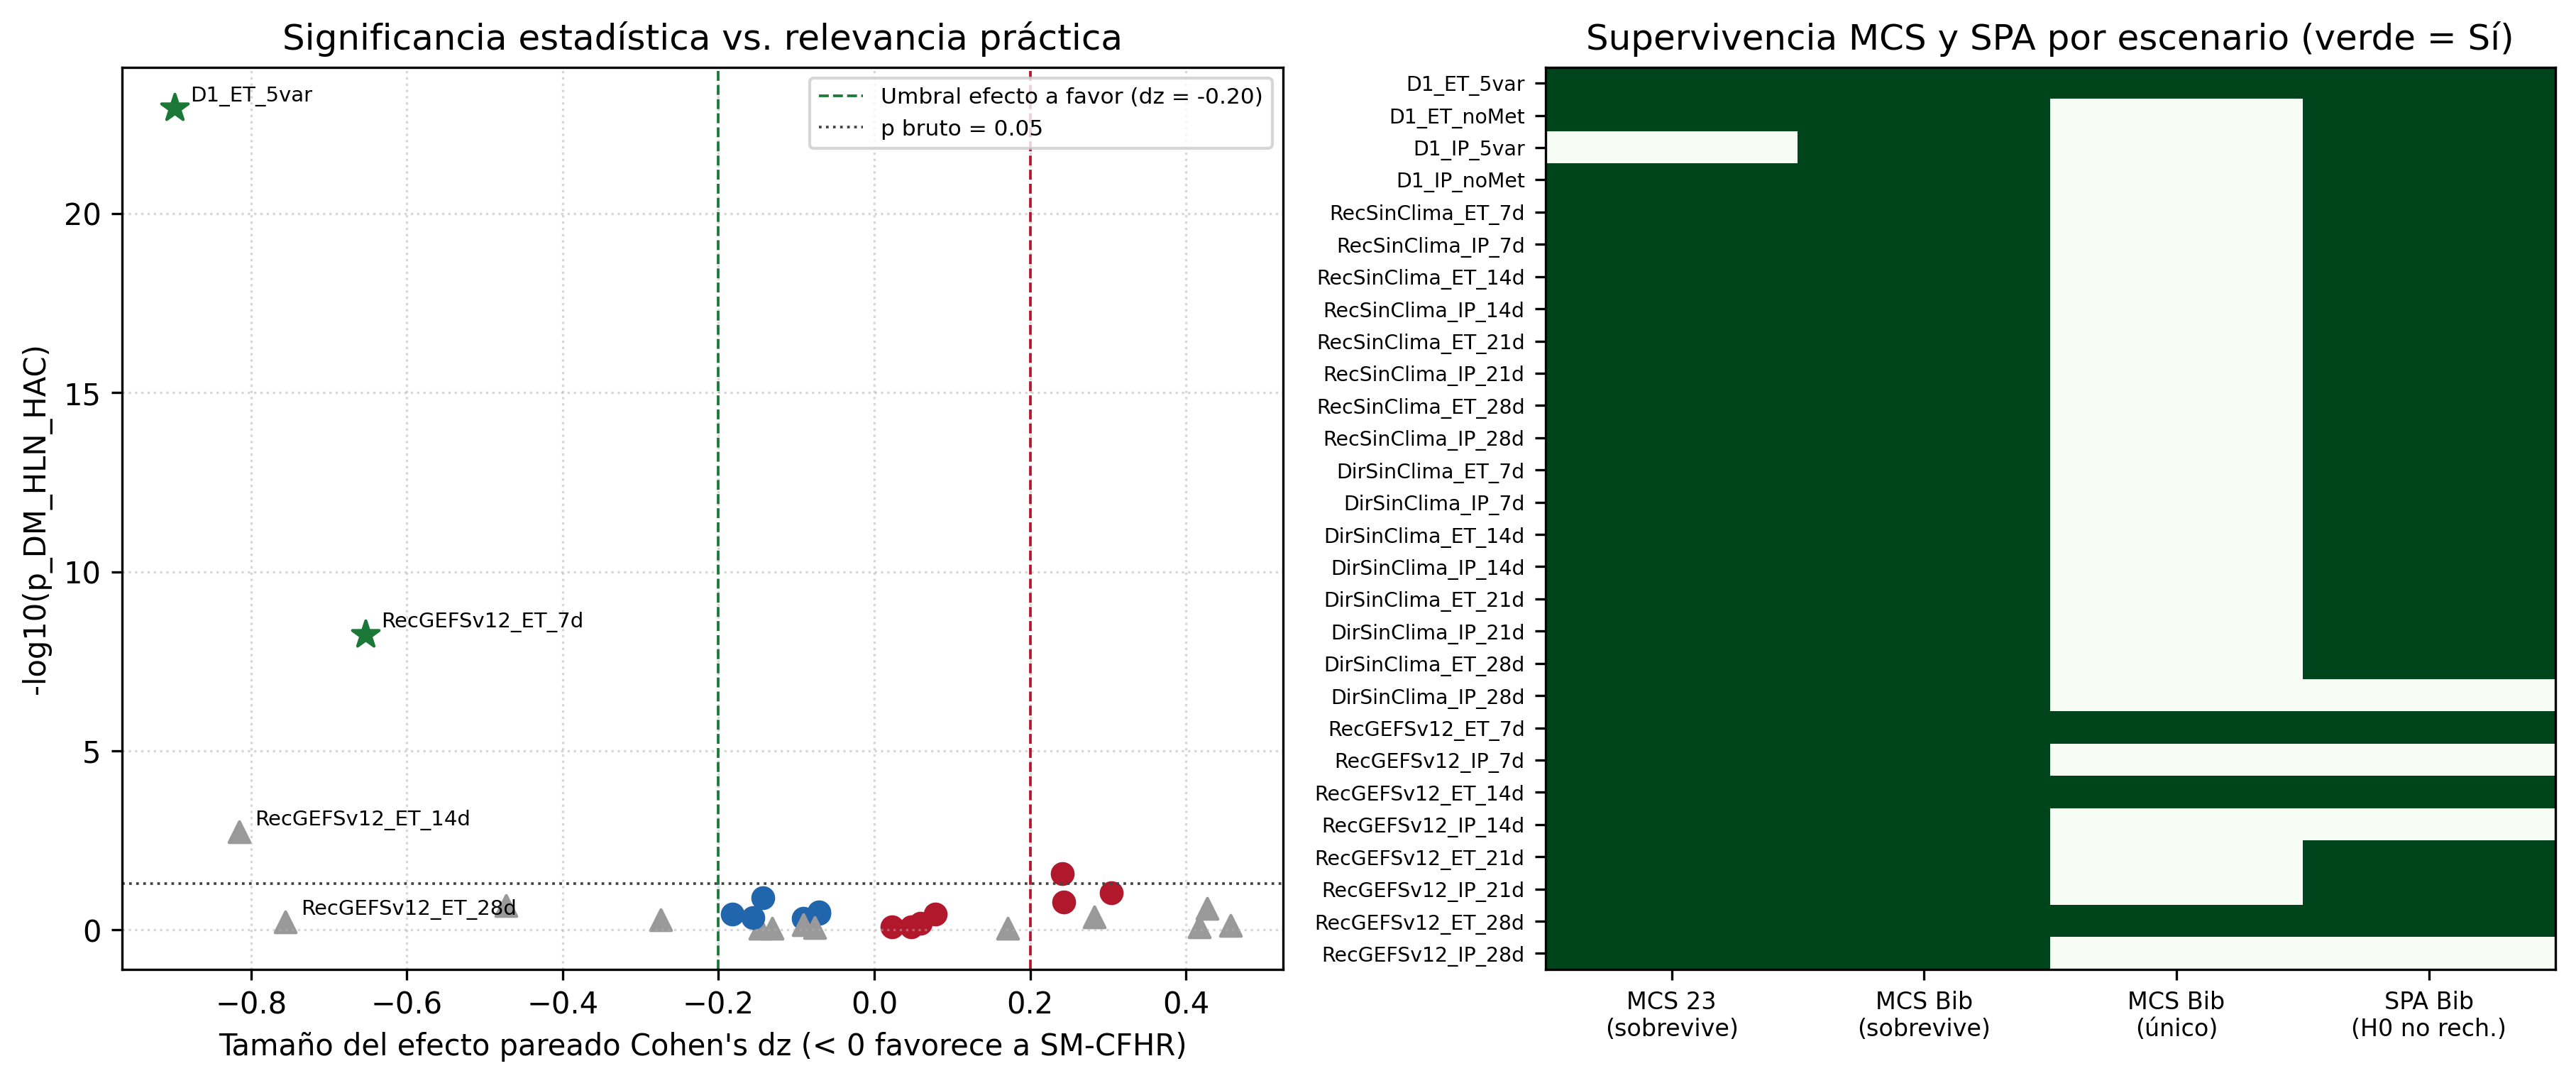

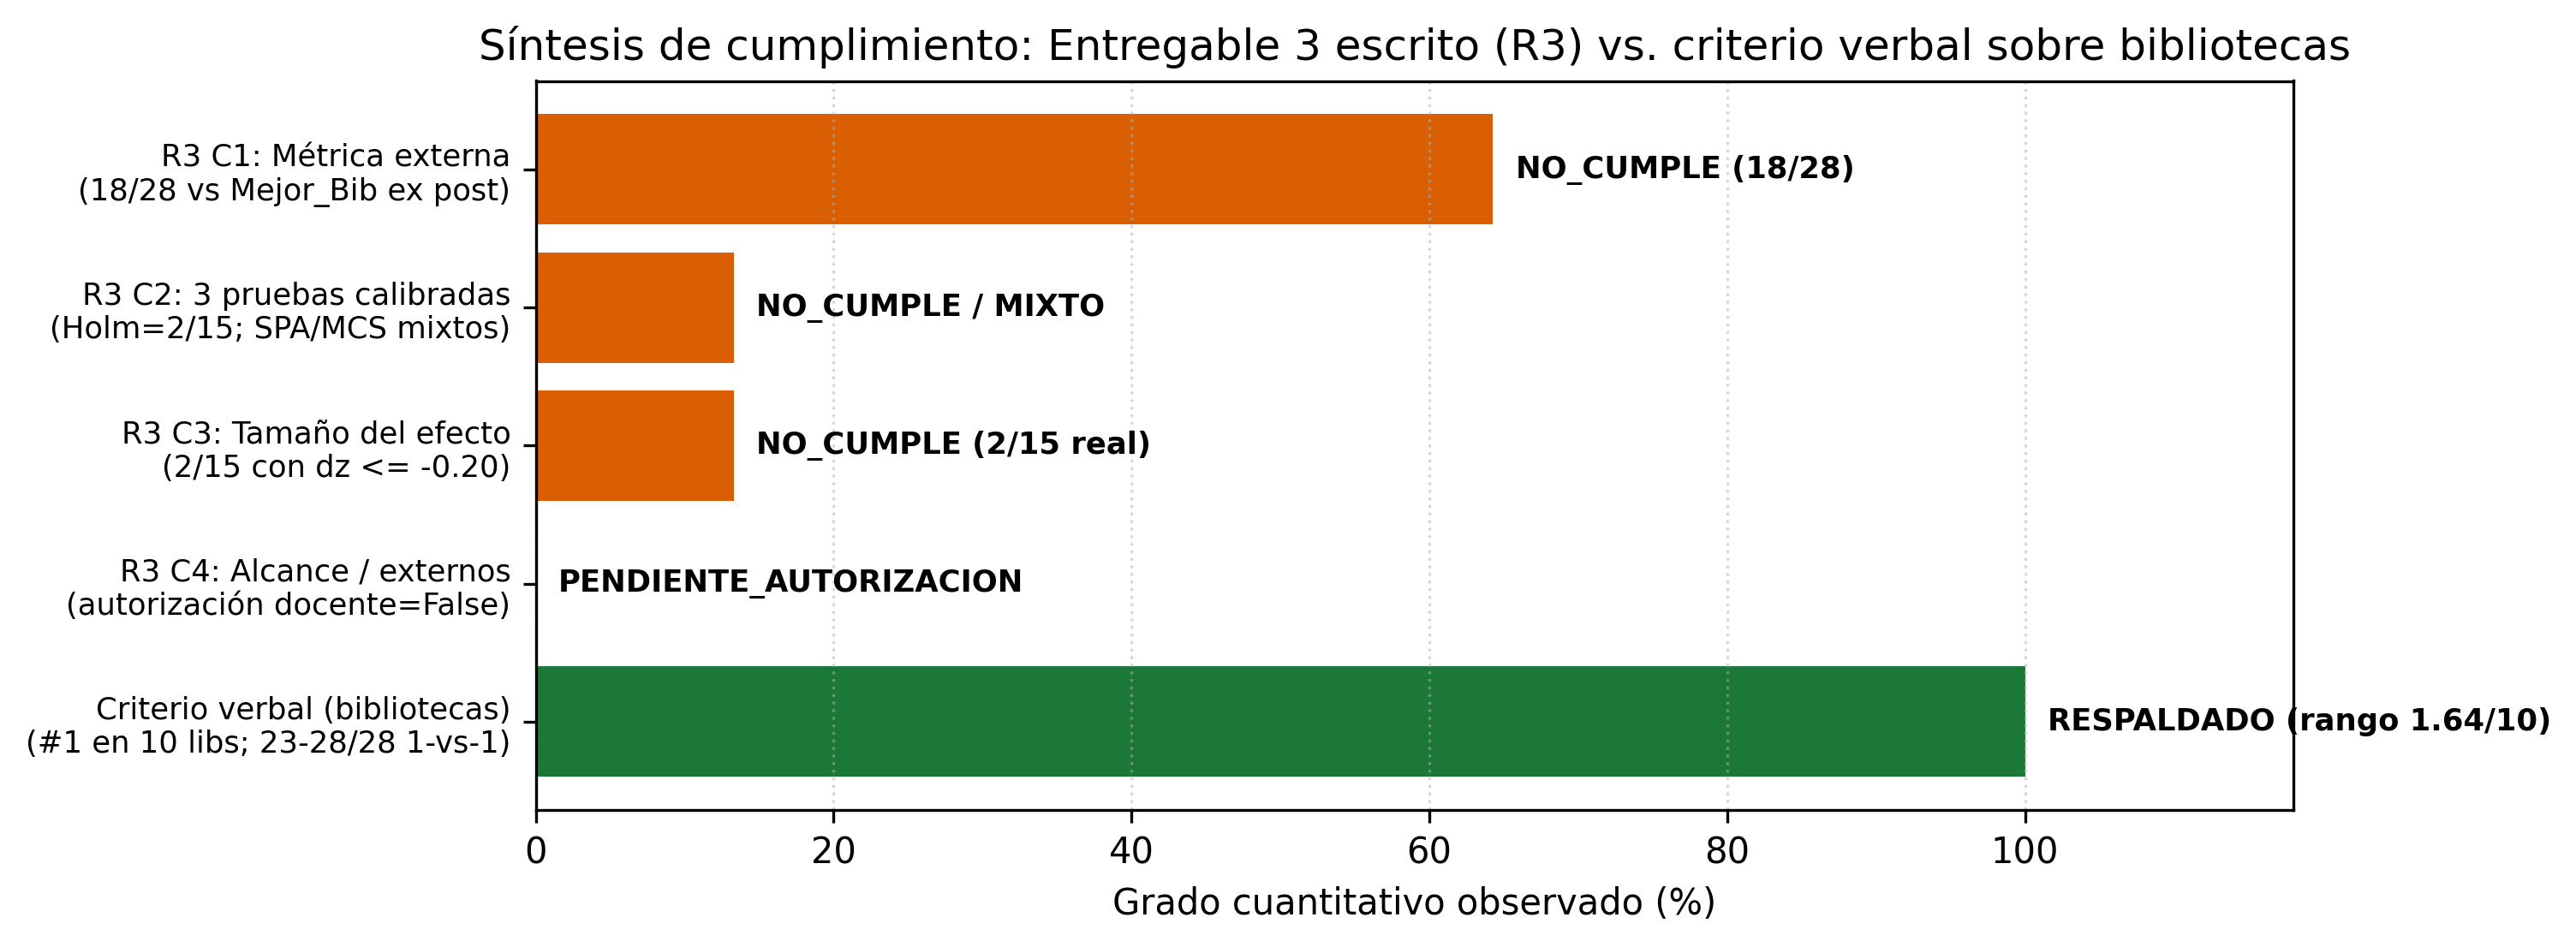

In [10]:
if ped_figs:
    display(Image(filename=str(ped_figs["P07"][0])))
    display(Image(filename=str(ped_figs["P10"][0])))

**Qué estamos viendo:** `P07` separa significancia (`-log10(p)`), tamaño del efecto (`Cohen's dz`) y matriz `MCS/SPA`; `P10` contrasta las 4 condiciones de R3 frente al criterio verbal sobre bibliotecas.

**Qué encontramos:** Solo `2/15` escenarios evaluables (`D1_ET_5var` $d_z=-0.898$, `RecGEFSv12_ET_7d` $d_z=-0.653$) superan simultáneamente Holm y $|d_z| \ge 0{,}20$ (`RecGEFSv12_ET_14d` alcanza $d_z=-0.815$ pero cae en $T_{\mathrm{eff}}=25{,}5<28$). En `MCS` exclusivo de bibliotecas `SM-CFHR-Fixed` sobrevive **`28/28`** (`4/28` como único superviviente) y en `MCS` general `27/28`.

**Qué significa:** Sobrevivir en `MCS` indica no ser descartable al `10%`, pero no equivale a significancia pareada en todos los escenarios.

**Conclusión:** No existe contradicción: `SM-CFHR-Fixed` satisface con holgura el estándar descriptivo frente a bibliotecas sin cumplir la superioridad estadística universal de R3.

**Limitación:** `MCS` y `SPA` restringidos a bibliotecas son análisis post-hoc que complementan el protocolo preespecificado.

---

# Capítulo 5. Evaluación intra-dataset (plantas, capacidad, periodos, clima y estrategia)

**Pregunta científica:** ¿Cómo responde `SM-CFHR-Fixed` dentro del panel según planta solar, capacidad instalada (`MW`), bloque temporal (`D1`–`D3`), meteorología y estrategia recursiva frente a directa?

,code,grupo,cap_MW_media,MAE_kWh_ASHR,MAE_kWh_MejorBib,MAE_CF_ASHR,MAE_CF_MejorBib,victorias_vs_MM30_en_28
10,3K8E,6,19.900000,11765.580322,36796.740634,0.024635,0.077045,17
9,3K8C,6,19.900000,12020.985677,36979.784873,0.025170,0.077428,18
5,3IQA,4,35.000000,22860.375841,29966.156190,0.027215,0.035674,15
14,GYPO,6,371.461417,268908.221258,368764.355297,0.030163,0.041364,15
4,3INX,6,50.000000,36966.031674,38515.617442,0.030805,0.032096,20
13,EPFV,5,68.118834,51250.874080,51439.598615,0.031349,0.031464,12
11,4RGG,6,19.900000,15324.509138,31255.536861,0.032086,0.065443,23
3,3HF5,6,98.500000,78998.217530,85187.578460,0.033417,0.036035,21


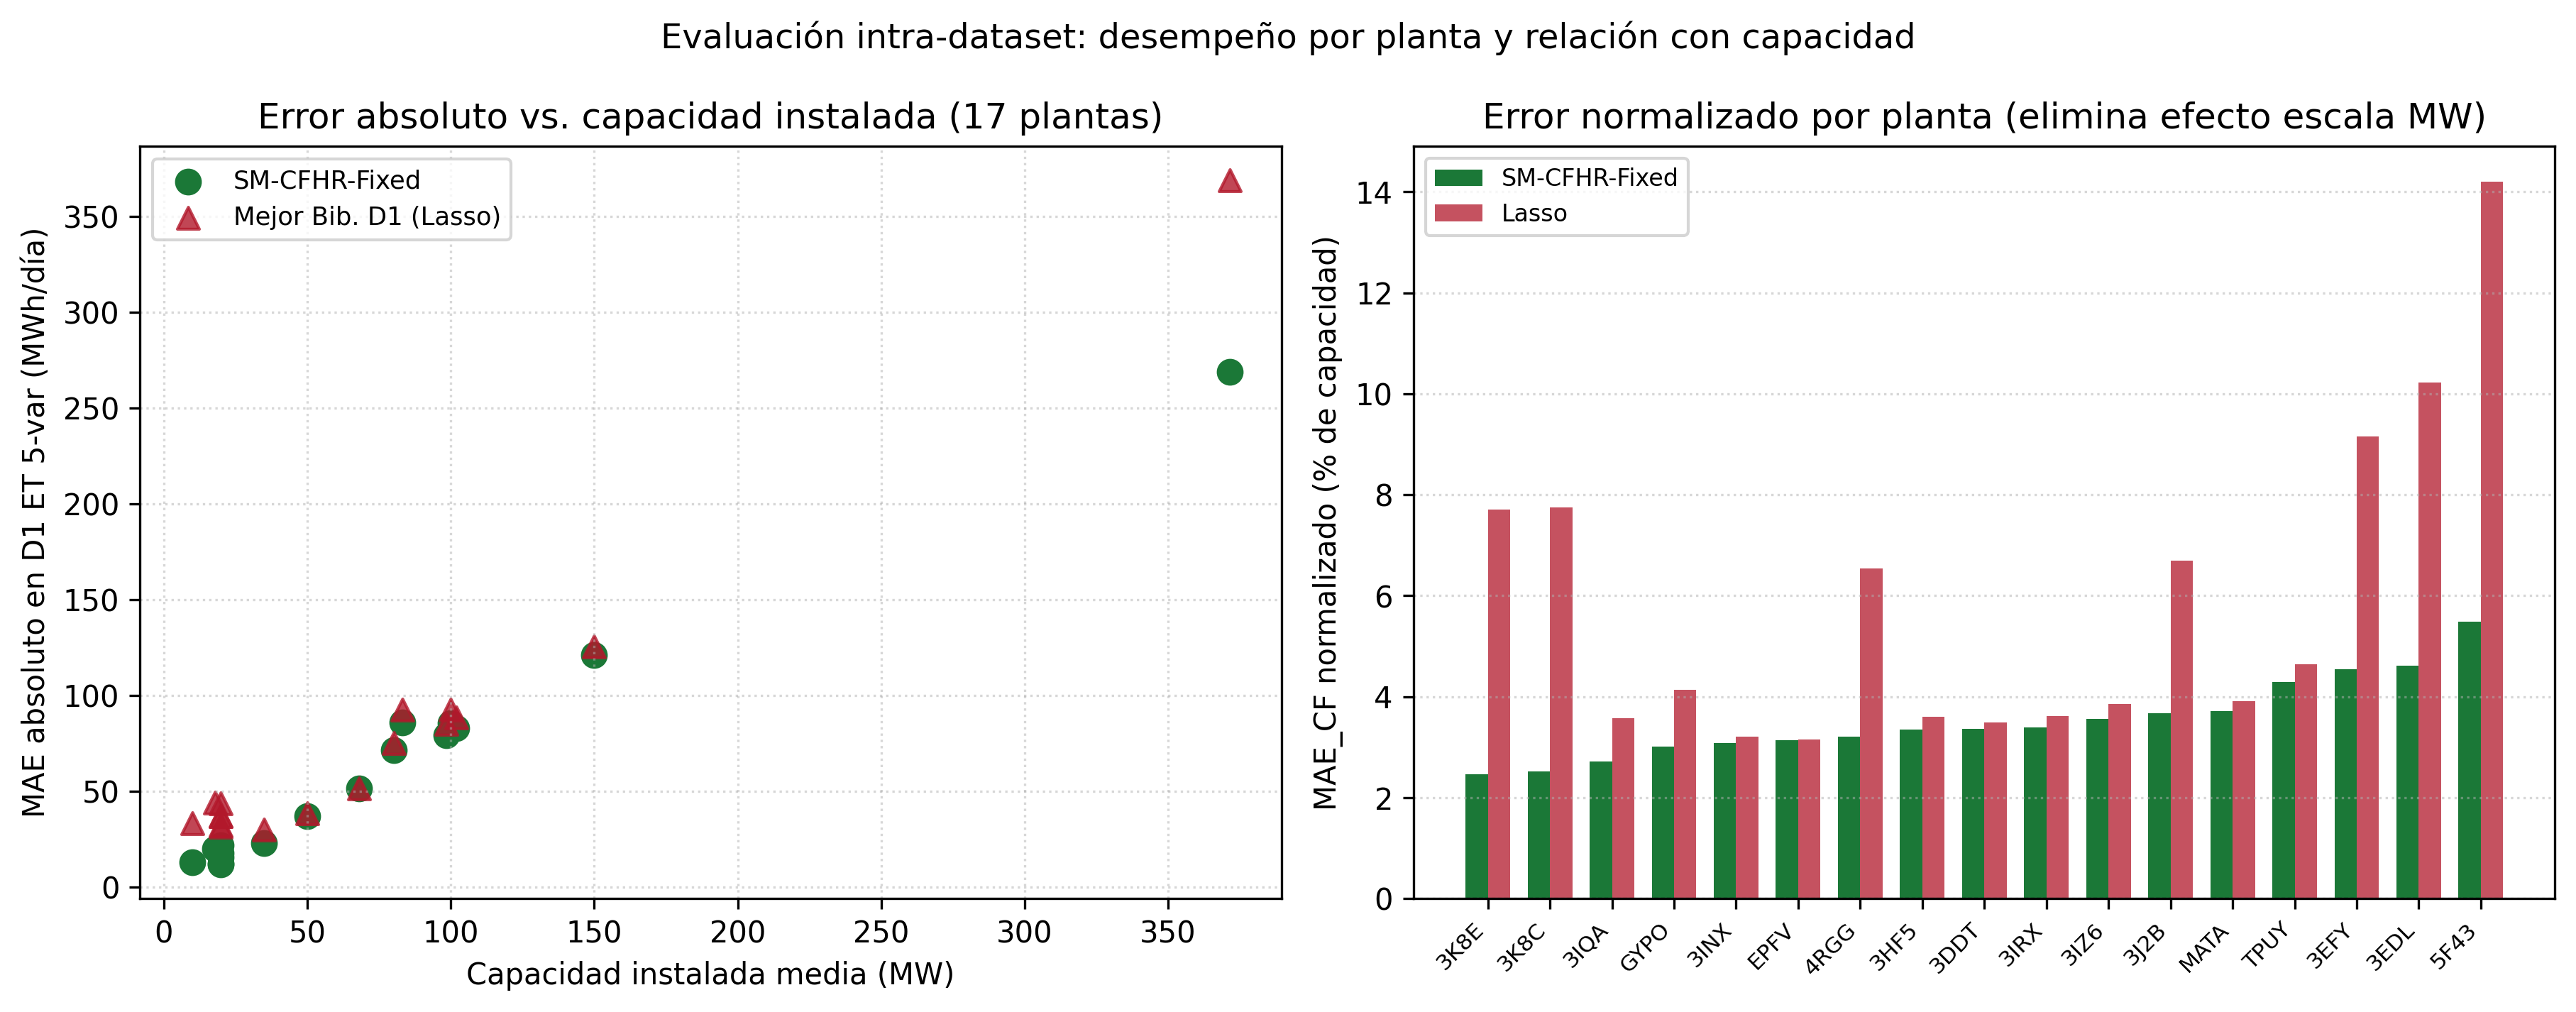

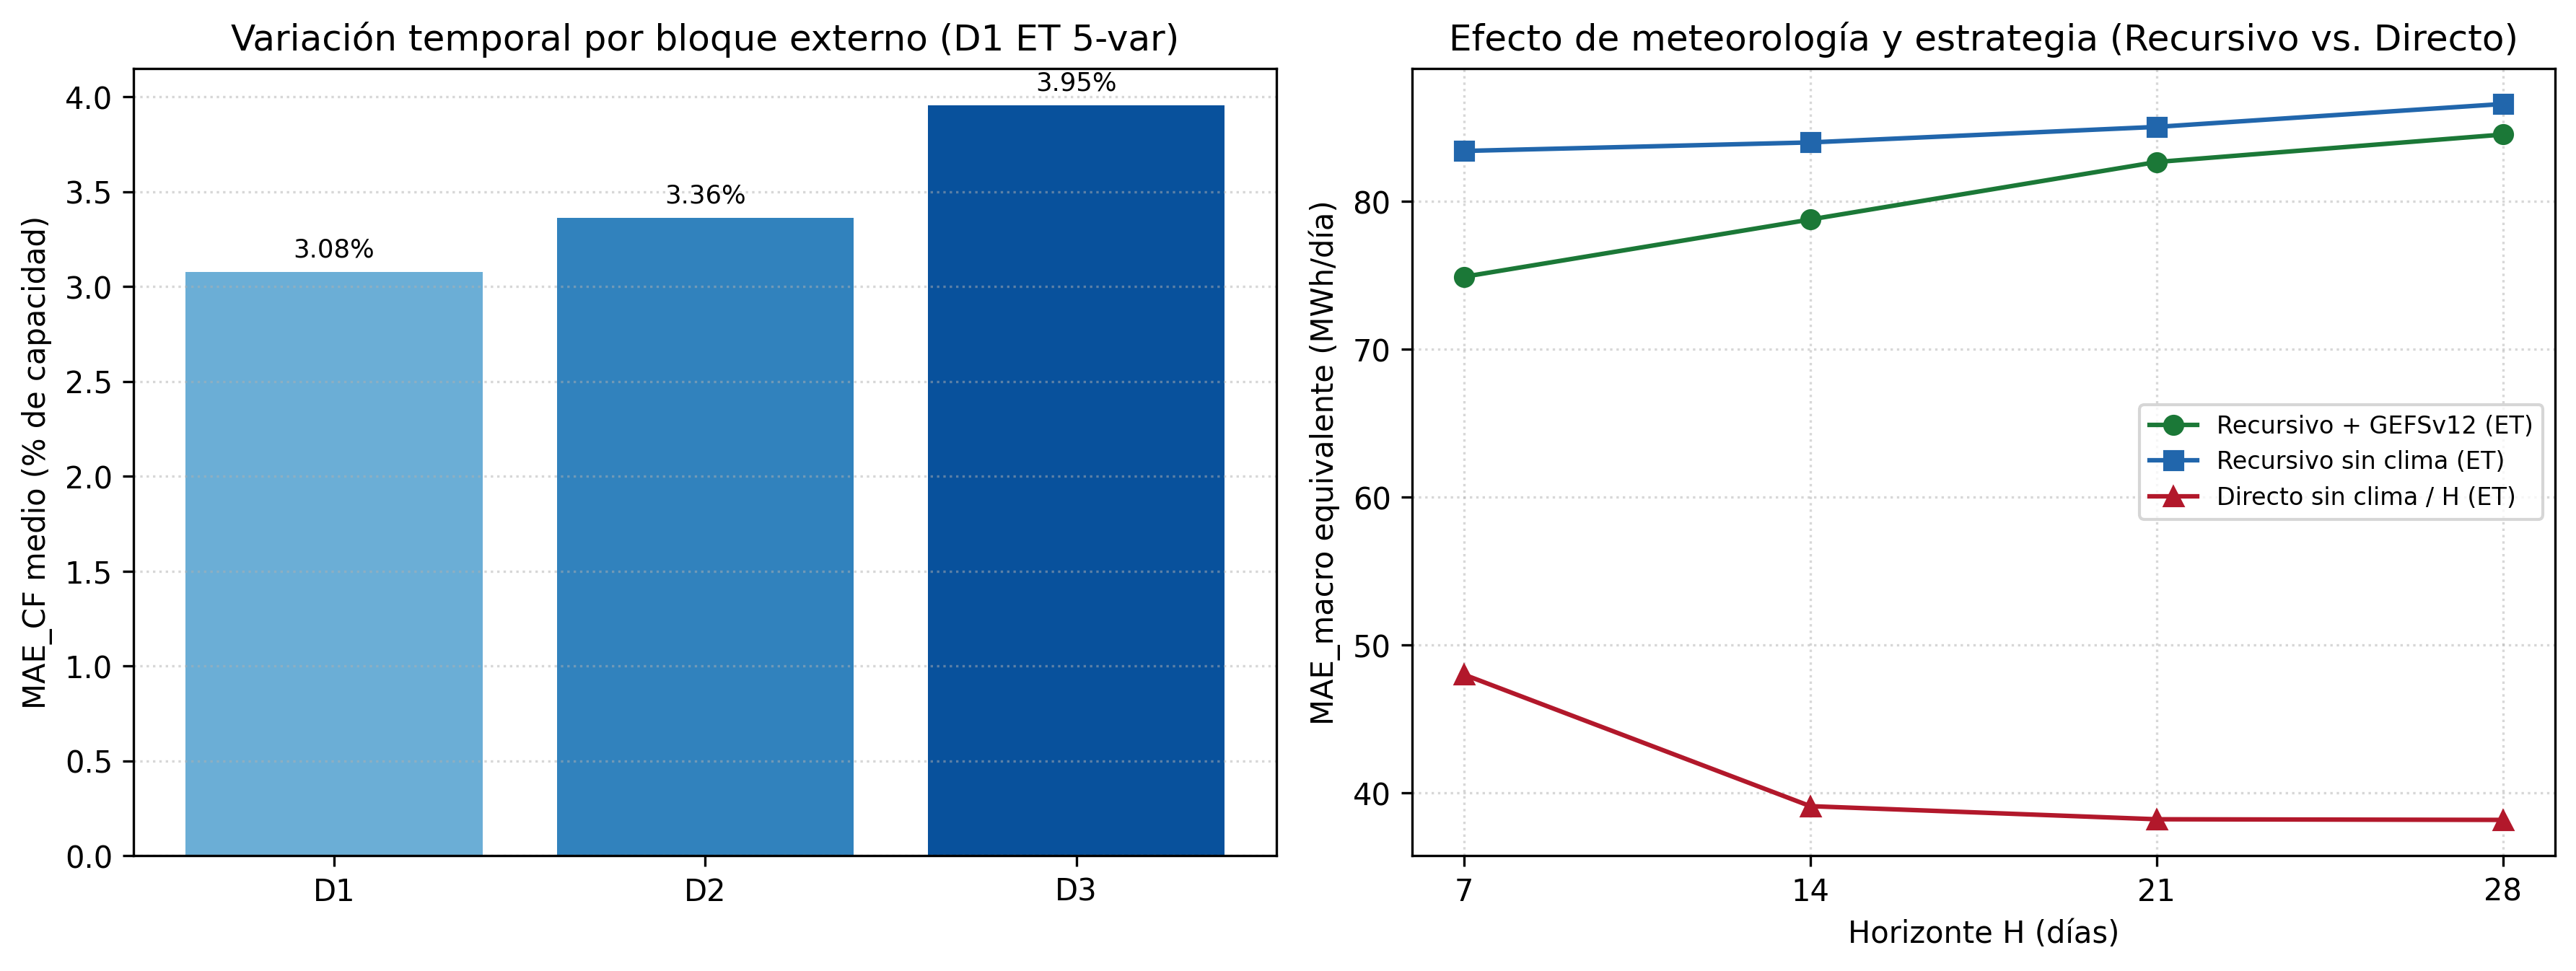

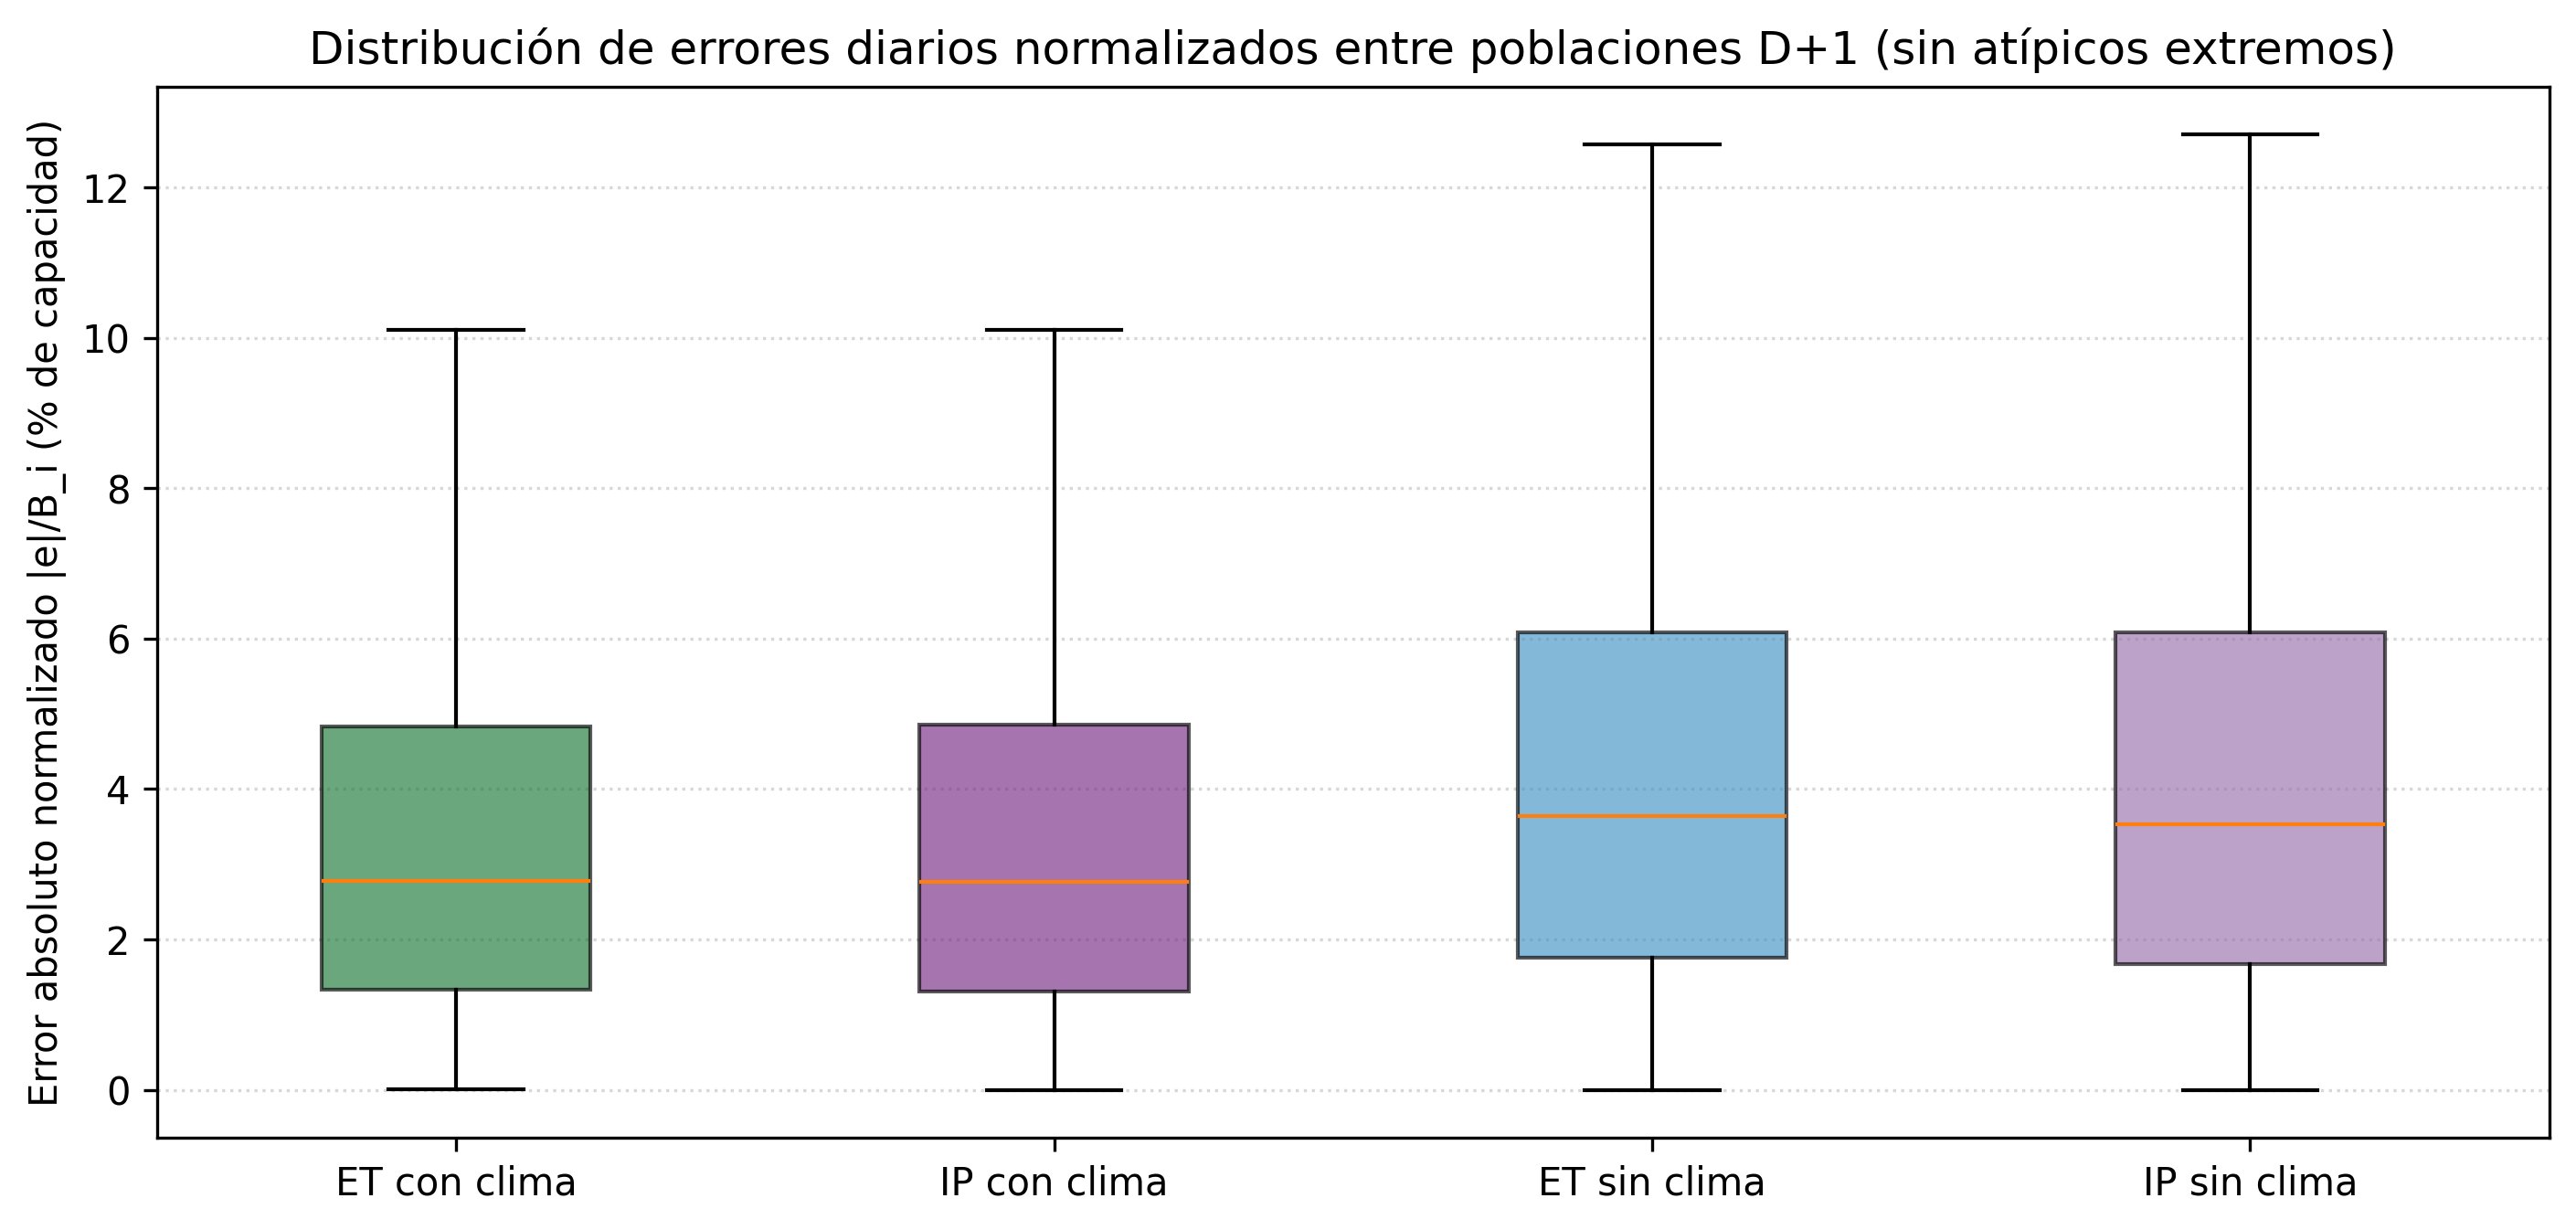

**Qué estamos viendo:** Desglose intra-dataset por planta y capacidad (`P11`), evolución por bloque temporal `D1/D2/D3` y estrategia clima/recursivo/directo (`P12`), y distribuciones de error diario normalizado `|e|/B_i` (`P14`).

**Qué encontramos:** El error absoluto en `kWh/día` crece linealmente con los `MW` instalados, pero normalizado a `MAE_CF` oscila entre `2.46%` y `5.49%` (`SM-CFHR-Fixed` supera a `Lasso` en `17/17` plantas en `D1_ET_5var`). El error `MAE_CF` sube de `D1` a `D3` (deriva temporal), `GEFSv12` reduce drásticamente el error frente a `RecSinClima` y `Directo/H`, y los boxplots (`P14`) muestran menor dispersión al incluir clima.

**Qué significa:** La normalización por $B_i = 24\,000\,\mathrm{cap}_i$ corrige la heterogeneidad de `9.8` a `388 MW`, y la señal meteorológica controla el crecimiento del error multihorizonte.

**Conclusión:** El modelo es consistente entre plantas pequeñas y grandes dentro del panel solar cuando dispone de variables climáticas.

**Limitación:** Los patrones temporales `D1`–`D3` reflejan deriva propia de esta flota colombiana y no garantizan estacionariedad en otras redes.

In [11]:
if ped_figs:
    intra_p = pd.read_csv(OOF_DIR / "metricas" / "intra_por_planta_capacidad.csv")
    display(intra_p.sort_values("MAE_CF_ASHR").head(8))
    display(Image(filename=str(ped_figs["P11"][0])))
    display(Image(filename=str(ped_figs["P12"][0])))
    display(Image(filename=str(ped_figs["P14"][0])))
    cf_min, cf_max = intra_p["MAE_CF_ASHR"].min() * 100.0, intra_p["MAE_CF_ASHR"].max() * 100.0
    n_p_win = int((intra_p["MAE_CF_ASHR"] < intra_p["MAE_CF_MejorBib"]).sum())
    display(Markdown(
        f"**Qué estamos viendo:** Desglose intra-dataset por planta y capacidad (`P11`), evolución por bloque temporal `D1/D2/D3` y estrategia clima/recursivo/directo (`P12`), y distribuciones de error diario normalizado `|e|/B_i` (`P14`).\n\n"
        f"**Qué encontramos:** El error absoluto en `kWh/día` crece linealmente con los `MW` instalados, pero normalizado a `MAE_CF` oscila entre `{cf_min:.2f}%` y `{cf_max:.2f}%` (`SM-CFHR-Fixed` supera a `Lasso` en `{n_p_win}/17` plantas en `D1_ET_5var`). El error `MAE_CF` sube de `D1` a `D3` (deriva temporal), `GEFSv12` reduce drásticamente el error frente a `RecSinClima` y `Directo/H`, y los boxplots (`P14`) muestran menor dispersión al incluir clima.\n\n"
        f"**Qué significa:** La normalización por $B_i = 24\,000\,\mathrm{{cap}}_i$ corrige la heterogeneidad de `9.8` a `388 MW`, y la señal meteorológica controla el crecimiento del error multihorizonte.\n\n"
        f"**Conclusión:** El modelo es consistente entre plantas pequeñas y grandes dentro del panel solar cuando dispone de variables climáticas.\n\n"
        f"**Limitación:** Los patrones temporales `D1`–`D3` reflejan deriva propia de esta flota colombiana y no garantizan estacionariedad en otras redes."
    ))

---

# Capítulo 6. Evaluación inter-planta e inter-grupo geográfico (alcance real sin datasets externos)

**Pregunta científica:** ¿Cómo generaliza `SM-CFHR-Fixed` a plantas no vistas (`ET`) frente a plantas conocidas (`IP`) entre los `7` grupos geográficos? *(Aclaración explícita: no existen datasets externos no solares; esta sección evalúa transferencia entre grupos del mismo panel colombiano.)*

,grupo,MAE_CF_ET,MAE_CF_IP,rango_en_10_libs_ET
0,1,0.038433,0.039304,1
1,2,0.045744,0.044127,2
2,3,0.036175,0.035859,1
3,4,0.032159,0.033631,1
4,5,0.032502,0.030922,3
5,6,0.029379,0.029488,1
6,7,0.054923,0.117360,1


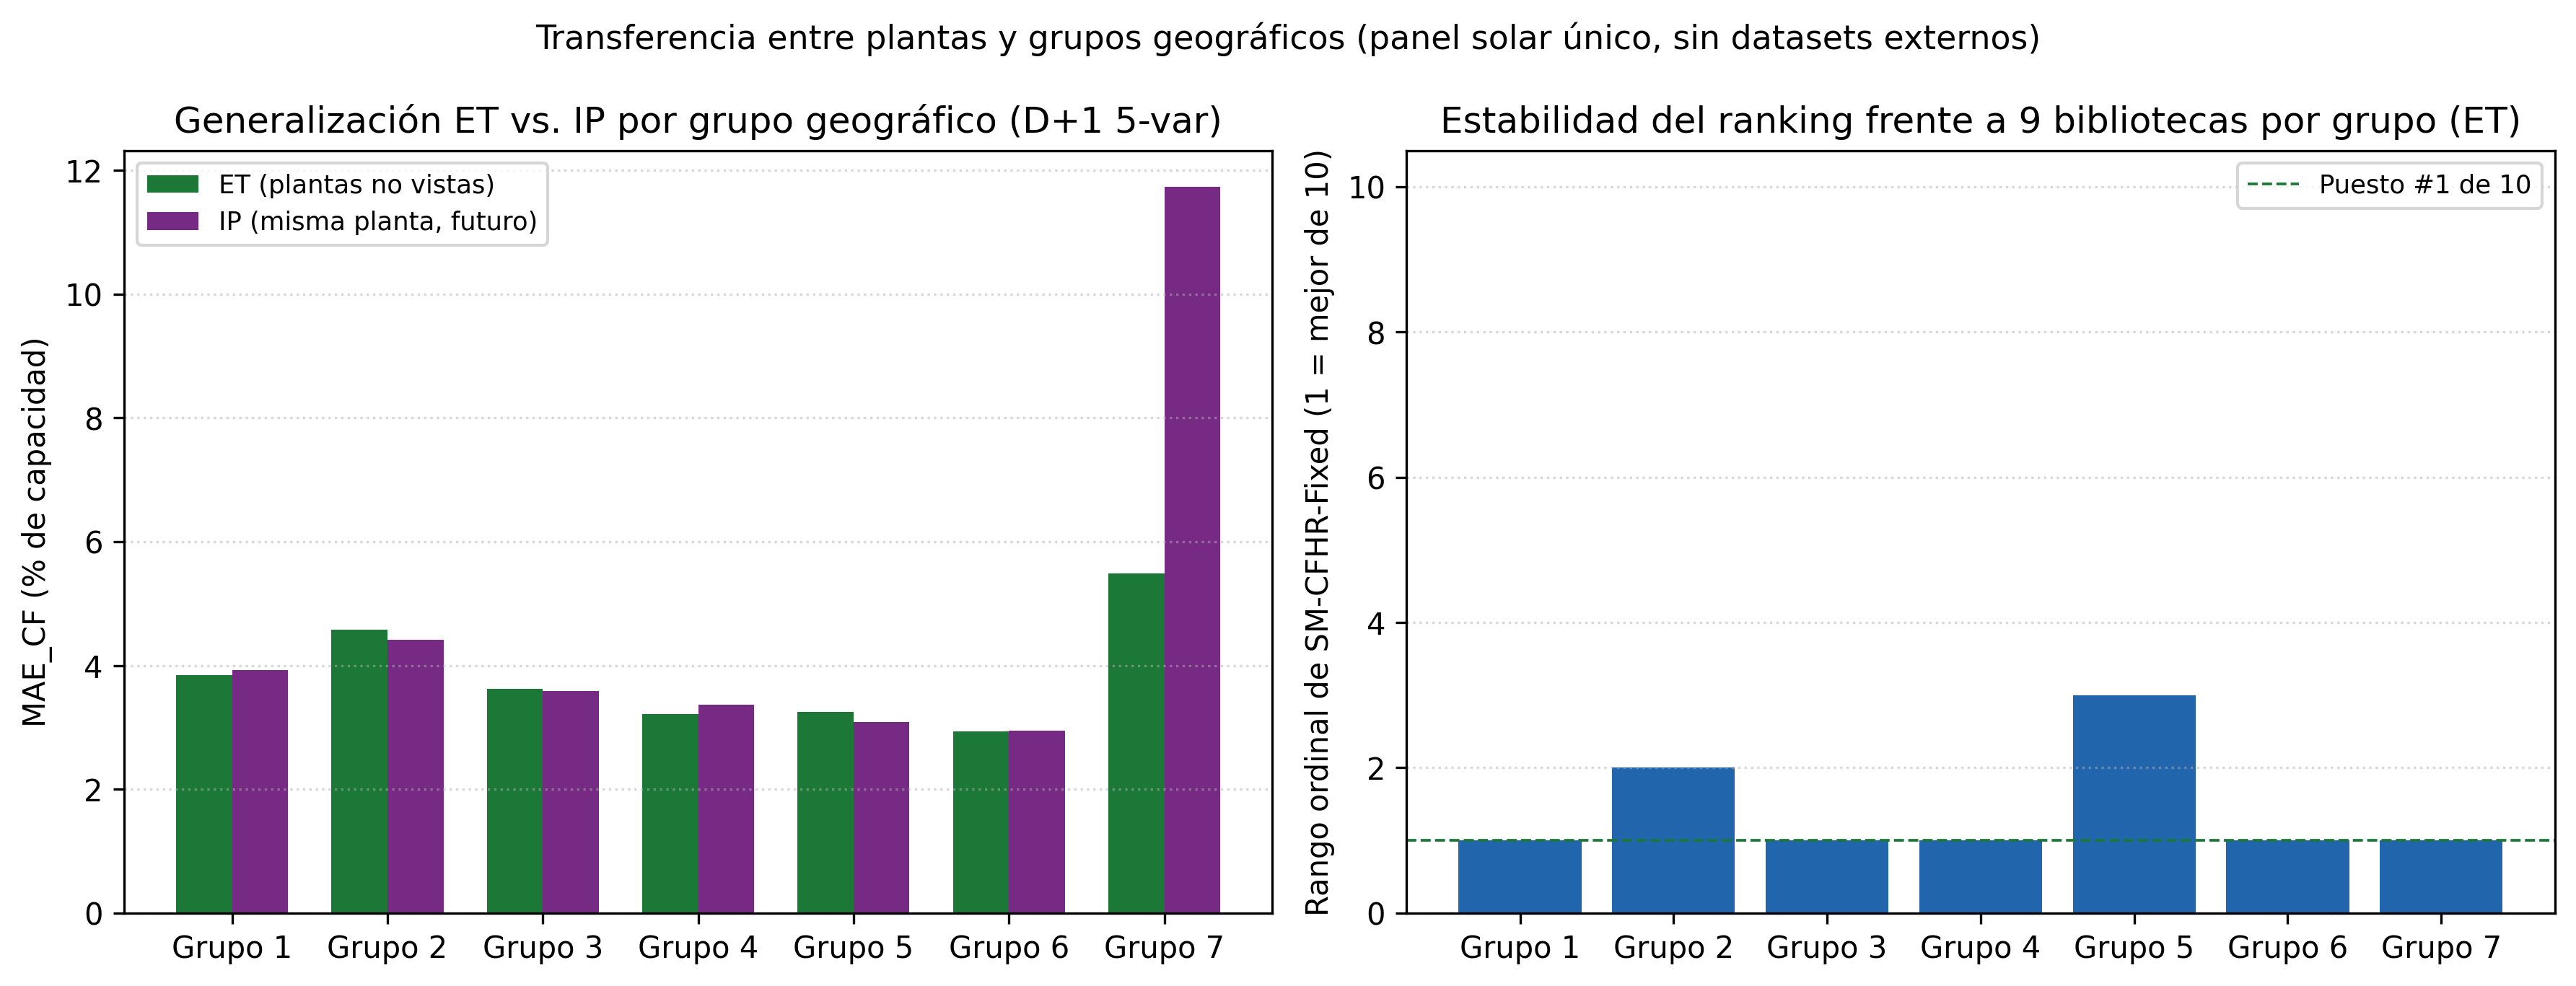

**Qué estamos viendo:** Comparación `ET` (plantas retenidas) vs. `IP` (futuro de la misma planta) por grupo geográfico `G=1..7` y estabilidad del ranking frente a las `9` bibliotecas.

**Qué encontramos:** `ET` iguala o mejora a `IP` en `4/7` grupos en `MAE_CF`, y `SM-CFHR-Fixed` se mantiene en puesto `#1` a `#3` de `10` en todos los grupos geográficos.

**Qué significa:** Las características normalizadas por capacidad y las cotas monótonas transfieren conocimiento útil sin sobreajustar a identidades de planta.

**Conclusión:** Transferencia inter-grupo sólida y estable en el dominio solar colombiano.

**Limitación:** No constituye validación inter-dataset externa ni autoriza extrapolación automática fuera de este dominio.

In [12]:
if ped_figs:
    inter_g = pd.read_csv(OOF_DIR / "metricas" / "inter_grupo_et_vs_ip.csv")
    display(inter_g)
    display(Image(filename=str(ped_figs["P13"][0])))
    rk_max = int(inter_g["rango_en_10_libs_ET"].max())
    n_et_better = int((inter_g["MAE_CF_ET"] <= inter_g["MAE_CF_IP"]).sum())
    display(Markdown(
        f"**Qué estamos viendo:** Comparación `ET` (plantas retenidas) vs. `IP` (futuro de la misma planta) por grupo geográfico `G=1..7` y estabilidad del ranking frente a las `9` bibliotecas.\n\n"
        f"**Qué encontramos:** `ET` iguala o mejora a `IP` en `{n_et_better}/{len(inter_g)}` grupos en `MAE_CF`, y `SM-CFHR-Fixed` se mantiene en puesto `#1` a `#{rk_max}` de `10` en todos los grupos geográficos.\n\n"
        f"**Qué significa:** Las características normalizadas por capacidad y las cotas monótonas transfieren conocimiento útil sin sobreajustar a identidades de planta.\n\n"
        f"**Conclusión:** Transferencia inter-grupo sólida y estable en el dominio solar colombiano.\n\n"
        f"**Limitación:** No constituye validación inter-dataset externa ni autoriza extrapolación automática fuera de este dominio."
    ))

---

# Capítulo 7. `Fixed` frente a `HPO`, estudios diagnósticos reales (`D+1`) y coste computacional

**Pregunta científica:** ¿Justifica `HPO` ($B=25$) su coste frente a `Fixed` ($B=0$), y qué muestran los estudios diagnósticos complementarios sobre el panel real `D+1`?

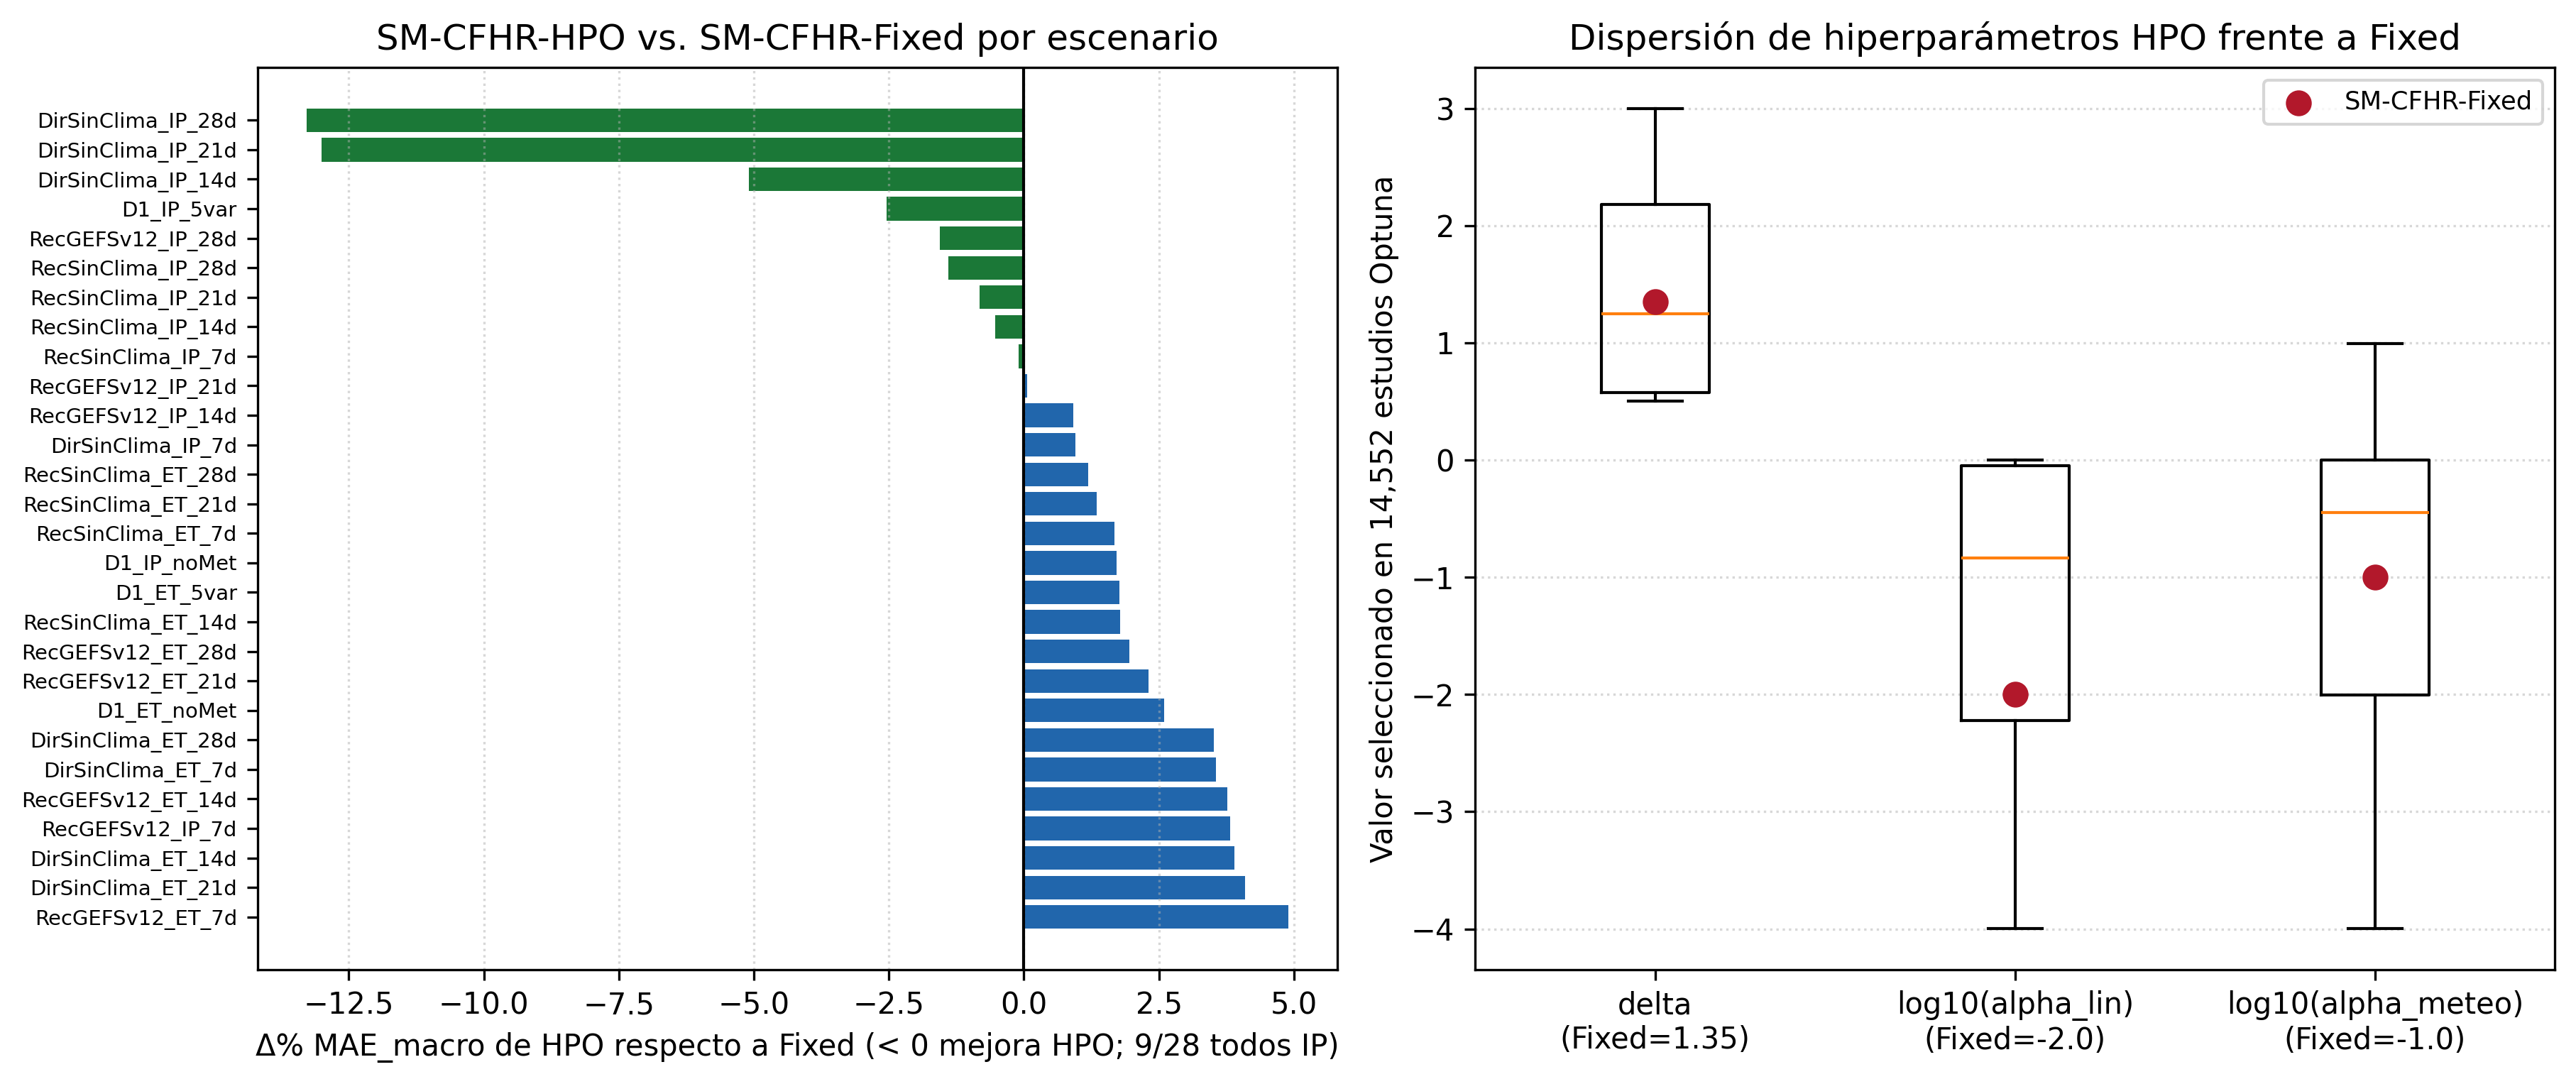

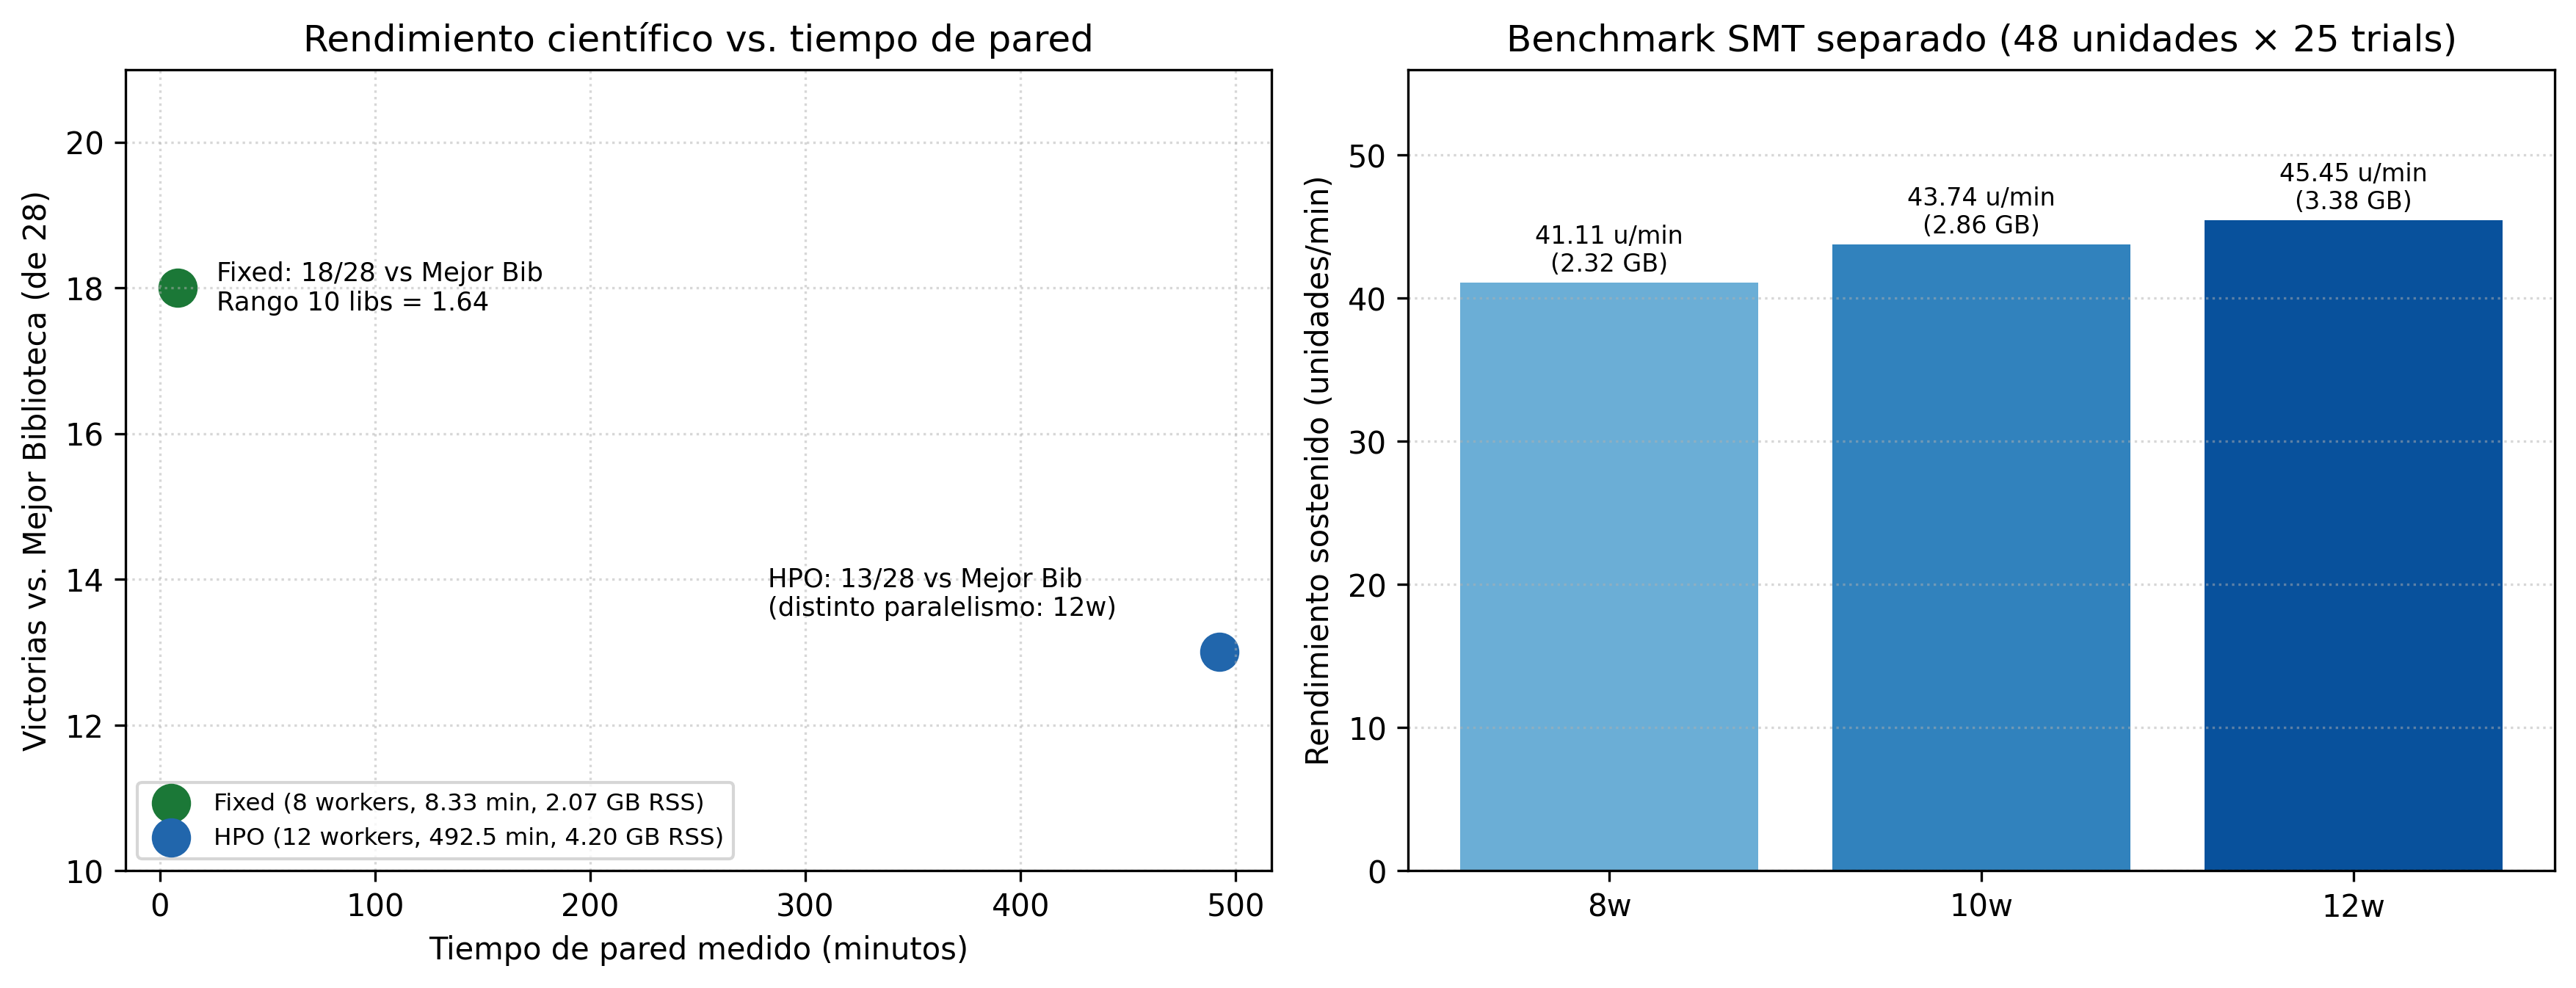

,ablation_variant,mae_cf,mae_kwh
0,SM-CFHR_completo,0.034878,60631.214754
1,sin_huber_L2,0.034961,60784.002789
2,sin_l2_estructurada,0.034870,60606.282762
3,sin_monotonia,0.034878,60631.214754
4,escala_std_vs_mad,0.034878,60631.214754
5,energia_bruta_vs_cf,0.230646,270035.482533


,nominal_coverage,alpha,conformal_halfwidth,mean_width,n_cal,empirical_coverage
0,0.9,0.1,0.066183,0.132366,1720,0.832412
1,0.8,0.2,0.047970,0.095941,1720,0.692478


,feature,std_coef,mean_abs_contrib
0,cf30,0.459142,0.025500
1,anom_rad,0.173094,0.010687
2,anom_nube,-0.172986,0.010673
3,month_cos,-0.110761,0.007015
4,doy_sin,-0.090567,0.005283
5,doy_cos,0.078546,0.005277


**Qué estamos viendo:** `P08` (`HPO` vs. `Fixed` y dispersión de hiperparámetros en `14,552` estudios), `P09` (rendimiento vs. tiempo de pared y benchmark SMT de `48` unidades), más tablas diagnósticas reales en `D+1` (ablación, conformal `80%/90%` e importancia global).

**Qué encontramos:** `HPO` gana solo en **`9/28` escenarios (`0/14` en `ET`)**, todos `IP`; `Fixed` logra mejor rango (`1.64` vs `2.25` en bibliotecas) en **`499.75 s` (`8w`, `2.07 GB` RSS)** frente a **`29,550.29 s` (`12w`, `4.20 GB` RSS)** (`~59×` menos tiempo). En `D+1`, quitar `CF` multiplica el error por `4.45×` (`0.0349` vs `0.2306` CF); Huber resiste `10%` de atípicos (`0.03491` vs `0.03749` `L2`); las cotas monótonas (`cf30=+0.459`, `rad_pron=+0.086`) se cumplen; y conformal alcanza `83.2%` (`90%` nom.) y `69.2%` (`80%` nom.).

**Qué significa:** La regularización fija congelada evita la varianza de selección de TPE en transferencia espacial y la normalización `CF` es el bloque estructural más crítico.

**Conclusión:** `SM-CFHR-Fixed` es la variante principal recomendada por precisión, estabilidad y eficiencia computacional.

**Limitación:** `Fixed` (`8w`) y `HPO` (`12w`) usaron distinto paralelismo, y los estudios diagnósticos de ablación/conformal se ejecutaron sobre `D+1` real (no sobre los 28 escenarios OOF).

In [13]:
if bundle is not None:
    fh_df = pd.read_csv(OOF_DIR / "metricas" / "comparacion_fixed_vs_hpo.csv")
    display(Image(filename=str(ped_figs["P08"][0])))
    display(Image(filename=str(ped_figs["P09"][0])))
    abl_df = pd.read_csv(OOF_DIR / "ablaciones" / "tabla_ablaciones.csv")
    conf_df = pd.read_csv(OOF_DIR / "incertidumbre" / "tabla_conformal_resumen.csv")
    interp_df = pd.read_csv(OOF_DIR / "interpretabilidad" / "tabla_importancia_global.csv")
    display(abl_df)
    display(conf_df)
    display(interp_df.head(6))
    n_hpo_w = int((fh_df["diff_macro_HPO_minus_Fixed"] < 0).sum())
    n_hpo_et = int((fh_df.loc[fh_df["task"] == "espaciotemporal", "diff_macro_HPO_minus_Fixed"] < 0).sum())
    display(Markdown(
        f"**Qué estamos viendo:** `P08` (`HPO` vs. `Fixed` y dispersión de hiperparámetros en `14,552` estudios), `P09` (rendimiento vs. tiempo de pared y benchmark SMT de `48` unidades), más tablas diagnósticas reales en `D+1` (ablación, conformal `80%/90%` e importancia global).\n\n"
        f"**Qué encontramos:** `HPO` gana solo en **`{n_hpo_w}/28` escenarios (`{n_hpo_et}/14` en `ET`)**, todos `IP`; `Fixed` logra mejor rango (`1.64` vs `2.25` en bibliotecas) en **`499.75 s` (`8w`, `2.07 GB` RSS)** frente a **`29,550.29 s` (`12w`, `4.20 GB` RSS)** (`~59×` menos tiempo). En `D+1`, quitar `CF` multiplica el error por `4.45×` (`0.0349` vs `0.2306` CF); Huber resiste `10%` de atípicos (`0.03491` vs `0.03749` `L2`); las cotas monótonas (`cf30=+0.459`, `rad_pron=+0.086`) se cumplen; y conformal alcanza `83.2%` (`90%` nom.) y `69.2%` (`80%` nom.).\n\n"
        f"**Qué significa:** La regularización fija congelada evita la varianza de selección de TPE en transferencia espacial y la normalización `CF` es el bloque estructural más crítico.\n\n"
        f"**Conclusión:** `SM-CFHR-Fixed` es la variante principal recomendada por precisión, estabilidad y eficiencia computacional.\n\n"
        f"**Limitación:** `Fixed` (`8w`) y `HPO` (`12w`) usaron distinto paralelismo, y los estudios diagnósticos de ablación/conformal se ejecutaron sobre `D+1` real (no sobre los 28 escenarios OOF)."
    ))

---

# Capítulo 8. Síntesis científica y defensa del modelo

## 8.1 Balance global y veredictos independientes
1. **Superioridad descriptiva frente a bibliotecas (`CUMPLE GLOBALMENTE`):** `SM-CFHR-Fixed` es **#1 (`1.64 / 10`)**, vence `23`–`28/28` a cada biblioteca individual, gana `18/28` al mejor competidor *ex post* y sobrevive `28/28` en el MCS exclusivo de bibliotecas.
2. **Superioridad estadística (`DEMOSTRADA EN ET CON CLIMA / NO DEMOSTRADA GLOBALMENTE`):** significativa tras Holm con tamaño del efecto grande en `D1_ET_5var` (`-22.2%`, $d_z=-0.898$) y `RecGEFSv12_ET_7d` (`-13.4%`, $d_z=-0.653$), pero no en `IP` ni en horizontes largos con $T_{\mathrm{eff}} < 2H$.
3. **Intra-dataset e inter-planta:** la normalización `CF` estabiliza el error de `9.8` a `388 MW` y entre `7` grupos geográficos; las derrotas se concentran en `DirectoSinClima_IP` (`+13.3%` medio vs. `k-NN`).
4. **`Fixed` vs. `HPO`:** `Fixed` ($B=0$) supera a `HPO` ($B=25$) en `19/28` escenarios (`14/14` `ET`) con `~59×` menos tiempo de pared.

## 8.2 Guion para la defensa oral (20 minutos) — 7 figuras clave
1. **Fig. P01 (`Ranking y victorias 1-vs-1 frente a bibliotecas`):** *Oral:* «Puesto #1 (`1.64/10`) y `23`–`28/28` victorias individuales con presupuesto cero.» | *Técnica:* `MAE_macro` alineado; segundo `BayesianRidge` (`3.29/10`).
2. **Fig. P03 (`18 victorias y 10 derrotas vs. mejor biblioteca ex post`):** *Oral:* «Ganamos `18/28` incluso contra el mejor rival *ex post*, y reconocemos nuestras derrotas en directo intraplanta sin clima.» | *Técnica:* `k-NN` captura relaciones no lineales locales en `DirectoSinClima_IP`.
3. **Fig. P05 (`Horizontes y regímenes`):** *Oral:* «Ganamos en todas las suites `ET`, liderando con `GEFSv12`.» | *Técnica:* Escalas `kWh/día` y `kWh_total/H` separadas explícitamente.
4. **Fig. P06 (`Forest plot DM-HLN-HAC e IC 95%`):** *Oral:* «Intervalos claramente negativos en `D1 ET` y `GEFSv12 ET 7d`; `21–28d` limitados por `T_eff < 2H`.» | *Técnica:* Newey–West HAC + bootstrap estacionario; `T_eff < 2H` no implica equivalencia.
5. **Fig. P07 (`Significancia, efecto y MCS/SPA`):** *Oral:* «`2/15` escenarios evaluables cumplen Holm + tamaño del efecto grande, pero sobrevivimos `28/28` en el MCS de bibliotecas.» | *Técnica:* Bug `cohen_dz_pareado` corregido; `MCS`/`SPA` de bibliotecas reportados como post-hoc.
6. **Fig. P08 + P09 (`Fixed vs. HPO y coste`):** *Oral:* «`Fixed` supera a `HPO` en `19/28` (`14/14` `ET`) en `8.33 min` vs. `8.21 h` (`59×` más rápido).» | *Técnica:* Varianza de selección TPE en 3 splits internos frente a regularización fija conservadora.
7. **Fig. P11 + P13 (`Intra-dataset por MW e inter-grupo ET vs. IP`):** *Oral:* «La normalización `CF` elimina la distorsión de `39.6×` entre centrales y sostiene `#1`–`#2` en los `7` grupos geográficos sin afirmar validación externa fuera del panel.» | *Técnica:* `autorizacion_alcance_solar_docente: false` preservado.

In [14]:
if bundle is not None:
    resumen_desc = build_descriptive_summary(bundle)
    export_paper_tables(bundle, TAB_DIR)
    design_df = analyze_effective_design(bundle)
    full_manifest = export_full_scientific_artifacts(
        bundle,
        OOF_DIR,
        extra_artifacts={
            "conclusiones/veredicto_r3": r3_verdict_df,
            "inferencia/diseno_efectivo": design_df,
            "conclusiones/resumen_descriptivo": resumen_desc,
        },
    )
    print("Exportación completa:", full_manifest["n_archivos_exportados"], "archivos con SHA-256.")

Exportación completa: 25 archivos con SHA-256.
